<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-073a-data-reuploading.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 073a. A data re-uploading classifier

A classifier assigns a label to a data point after it has seen labelled examples. A neural network does this with a stack of layers, each an affine map of its input followed by a fixed nonlinear function. Here the data enter a quantum circuit as rotation angles, and a measurement of the qubit returns the label. How much a single qubit, whose state holds only two complex amplitudes, can learn in this way depends on how often the data are loaded. A circuit that loads the data once draws only straight decision boundaries. A circuit that loads them again in every layer, the data re-uploading classifier of Pérez-Salinas and co-workers [1], draws curved boundaries, and with enough layers it approximates any bounded function of the data [2].

We are given 400 labelled points in the square $[-1,1]^2$, with class 1 inside a circle, and a separate set of 4000 test points. We build the classifier on one qubit, train its angles with exact gradients from automatic differentiation and with the Adam optimiser [4], and measure the training and test accuracies as functions of the number of layers $L$. We follow single data points on the Bloch sphere through the layers of a trained circuit, and we explain the growth of the expressive power with $L$ by writing the circuit output as a Fourier series [3]. We then separate three classes with label states spread over the Bloch sphere, move to registers of several qubits whose orthogonal basis states serve as label states, and show in which situation an entangling gate between the qubits raises the accuracy.

Sections 1 to 13 and the classroom cell of Section 14 form the classroom route and run in about nine minutes on a laptop CPU. The switch `RUN_OPTIONAL` in the first code cell is `False` by default; the cells marked OPTIONAL then plot the recorded study instead of training. Setting it to `True` also trains the three-class classifier at further depths (Section 11), the entanglement experiment of Section 13 at all depths and the annulus comparison at all depths (Section 14.1), about fifteen more minutes in total, and prints the agreement with the recorded study. Section 15 lists exercises for home.

All results are exact state-vector simulations with fixed random seeds. On a quantum device the probability of an outcome would be estimated from repeated measurements, and Exercise 2 adds this shot noise.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`, on the CPU. JAX does the linear algebra, the automatic differentiation and the compiled training loops, NumPy generates the data, and Matplotlib draws the figures. The cells run in order.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # small calculations, never the GPU
import json, time
from pathlib import Path
import numpy as np
import jax
import jax.numpy as jnp
from jax import lax
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.patches import Rectangle, Arc, FancyArrowPatch

jax.config.update("jax_enable_x64", True)
CDTYPE = jnp.complex128
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
NAVY, BLUE, ORANGE, GRAY, GREEN = "#002B5C", "#3E8FD0", "#D35A05", "#5A6270", "#1B7F36"
plt.rcParams.update({"font.size": 13, "axes.labelsize": 14, "axes.titlesize": 13, "xtick.labelsize": 12,
                     "ytick.labelsize": 12, "legend.fontsize": 12, "figure.figsize": (4.8, 3.2),
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
CLASS_CMAP = ListedColormap(["#CFE3F5", "#F6CDAE"])                 # predicted class 0 / class 1
PROB_CMAP = LinearSegmentedColormap.from_list("p1", ["#3E8FD0", "#F4F4F4", "#D35A05"])
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)
started = time.perf_counter()
RESULTS = {}
print("JAX", jax.__version__, "| devices:", jax.devices())

RUN_OPTIONAL = False   # True also runs the OPTIONAL cells (Sections 11, 13 and 14); they print their agreement with the recorded study


JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. The classification task

Each data point is a vector $\mathbf x=(x_1,x_2)$ drawn uniformly from the square $[-1,1]^2$, and its label $y\in\{0,1\}$ says whether the point lies inside a circle centred at the origin. We choose the radius $r_0=\sqrt{2/\pi}\approx0.80$, so that the disc has the area $\pi r_0^2=2$, half the area of the square. Both classes then occur equally often, and a classifier that guesses reaches an accuracy of one half. The labels follow the rule
$$y(\mathbf x)=\begin{cases}1, & x_1^2+x_2^2<r_0^2,\\ 0, & \text{otherwise}.\end{cases} \tag{1}$$
The learner never sees this rule. It sees $M=400$ training pairs $(\mathbf x_m,y_m)$ with $m=1,\dots,M$, and it is judged on 4000 test points that it has never seen. The measure of success is the accuracy, the fraction of points whose predicted label equals the true one. A large gap between the training and the test accuracy would signal that the model memorises the training points.

training set: 400 points, fraction of class 1 = 0.502
test set:     4000 points, fraction of class 1 = 0.483


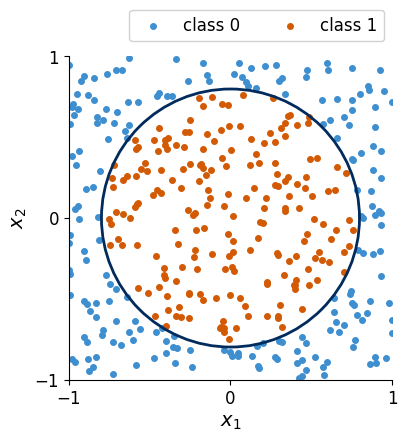

In [2]:
R2 = 2 / np.pi                                   # r_0^2, equal areas of the two classes
rng = np.random.default_rng(3)                   # data seed

def make_circle_data(M):
    X = rng.uniform(-1, 1, size=(M, 2))
    y = (np.sum(X ** 2, axis=1) < R2).astype(np.float64)       # rule (1)
    return X, y

Xtr, ytr = make_circle_data(400)
Xte, yte = make_circle_data(4000)
print(f"training set: {len(Xtr)} points, fraction of class 1 = {ytr.mean():.3f}")
print(f"test set:     {len(Xte)} points, fraction of class 1 = {yte.mean():.3f}")
assert abs(np.pi * R2 - 2.0) < TOL

def draw_circle(ax, r=np.sqrt(R2), **kw):
    ax.add_patch(plt.Circle((0, 0), r, fill=False, color=NAVY, lw=2, **kw))

def square_axes(ax):
    ax.set_aspect("equal"); ax.set_xlim(-1, 1); ax.set_ylim(-1, 1)
    ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1]); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")

fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.scatter(*Xtr[ytr == 0].T, s=16, color=BLUE, label="class 0")
ax.scatter(*Xtr[ytr == 1].T, s=16, color=ORANGE, label="class 1")
draw_circle(ax); square_axes(ax)
ax.legend(frameon=True, framealpha=0.9, loc="upper right", bbox_to_anchor=(1.0, 1.17), ncol=2)
save(fig, "fig_lab073a_data"); plt.show()

The orange points of class 1 fill the disc, and the blue points of class 0 fill the four corners of the square. No straight line separates the two classes, so a classifier that can only draw straight boundaries fails, and a useful model has to produce a closed, curved boundary.

## 3. One qubit and its rotations

A qubit is a two-level quantum system. Its state is a normalised vector of two complex amplitudes,
$$|\psi\rangle=a|0\rangle+b|1\rangle=\begin{pmatrix}a\\ b\end{pmatrix},\qquad |a|^2+|b|^2=1, \tag{2}$$
and a measurement in the computational basis returns the outcome 0 with probability $|a|^2$ and the outcome 1 with probability $|b|^2$. A common phase factor $e^{i\gamma}$ of both amplitudes changes no probability, so two real angles describe the state, $a=\cos(\vartheta/2)$ and $b=e^{i\varphi}\sin(\vartheta/2)$. These are the polar angle $\vartheta$ and the azimuth $\varphi$ of a point on the unit sphere, the Bloch sphere, with $|0\rangle$ at the north pole and $|1\rangle$ at the south pole. The Cartesian coordinates of the point form the Bloch vector
$$\mathbf r=\big(\langle\hat X\rangle,\langle\hat Y\rangle,\langle\hat Z\rangle\big)=\big(2\,\mathrm{Re}(a^*b),\ 2\,\mathrm{Im}(a^*b),\ |a|^2-|b|^2\big), \tag{3}$$
where $\hat X$, $\hat Y$, $\hat Z$ are the Pauli matrices and $\langle\hat A\rangle=\langle\psi|\hat A|\psi\rangle$ denotes an expectation value. The height of the point gives the probability of outcome 1, $|b|^2=(1-r_z)/2$, which is 0 at the north pole, 1 at the south pole and one half on the equator.

A gate is a unitary $2\times2$ matrix, and on the Bloch sphere it acts as a rotation. We need two of them, the rotations by an angle $\alpha$ about the $z$ axis and about the $y$ axis,
$$\hat R_z(\alpha)=e^{-i\alpha\hat Z/2}=\begin{pmatrix}e^{-i\alpha/2}&0\\ 0&e^{i\alpha/2}\end{pmatrix},\qquad
\hat R_y(\alpha)=e^{-i\alpha\hat Y/2}=\begin{pmatrix}\cos\frac{\alpha}{2}&-\sin\frac{\alpha}{2}\\ \sin\frac{\alpha}{2}&\cos\frac{\alpha}{2}\end{pmatrix}. \tag{4}$$
The gate $\hat R_z$ multiplies the two amplitudes by opposite phases. It leaves the probabilities unchanged and turns the Bloch vector about the vertical axis. The gate $\hat R_y$ mixes the two amplitudes and tilts the Bloch vector along a meridian. Three rotations about $z$, $y$ and $z$ produce every one-qubit gate up to a common phase (they are the Euler angles of a rotation), and we write this general gate as
$$\hat U(\boldsymbol\phi)=\hat R_z(\phi_3)\,\hat R_y(\phi_2)\,\hat R_z(\phi_1),\qquad \boldsymbol\phi=(\phi_1,\phi_2,\phi_3), \tag{5}$$
where $\hat R_z(\phi_1)$ acts first. For example, $\hat U(0,\pi/2,\pi/2)$ acting on $|0\rangle$ tilts the Bloch vector from the north pole to the point $(1,0,0)$ on the equator with $\hat R_y(\pi/2)$ and then turns it to $(0,1,0)$ with $\hat R_z(\pi/2)$. The code defines the matrices (4) and (5) and the Bloch vector (3) and checks these statements.

In [3]:
I2 = jnp.eye(2, dtype=CDTYPE)
PX = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
PY = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
PZ = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
KET0 = jnp.array([1.0, 0.0], dtype=CDTYPE)

def rz(a):                                          # equation (4)
    return jnp.array([[jnp.exp(-0.5j * a), 0], [0, jnp.exp(0.5j * a)]], dtype=CDTYPE)

def ry(a):                                          # equation (4)
    c, s = jnp.cos(a / 2), jnp.sin(a / 2)
    return jnp.array([[c, -s], [s, c]], dtype=CDTYPE)

def U(phi):                                         # equation (5), R_z(phi_1) acts first
    return rz(phi[2]) @ ry(phi[1]) @ rz(phi[0])

def bloch(psi):                                     # equation (3)
    a, b = psi[0], psi[1]
    return jnp.real(jnp.array([2 * jnp.conj(a) * b, -2j * jnp.conj(a) * b, jnp.abs(a) ** 2 - jnp.abs(b) ** 2]))

alpha = 0.83
assert jnp.allclose(rz(alpha), jnp.cos(alpha / 2) * I2 - 1j * jnp.sin(alpha / 2) * PZ, atol=TOL)
assert jnp.allclose(ry(alpha), jnp.cos(alpha / 2) * I2 - 1j * jnp.sin(alpha / 2) * PY, atol=TOL)
phi_test = jnp.array([0.3, -1.2, 2.1])
assert jnp.allclose(U(phi_test).conj().T @ U(phi_test), I2, atol=TOL)          # unitary
assert jnp.allclose(bloch(U(jnp.array([0.0, jnp.pi / 2, 0.0])) @ KET0), jnp.array([1.0, 0, 0]), atol=TOL)
assert jnp.allclose(bloch(U(jnp.array([0.0, jnp.pi / 2, jnp.pi / 2])) @ KET0), jnp.array([0, 1.0, 0]), atol=TOL)
psi_test = U(phi_test) @ KET0
r_test = bloch(psi_test)
assert abs(jnp.abs(psi_test[1]) ** 2 - (1 - r_test[2]) / 2) < TOL                 # |b|^2 = (1 - r_z)/2
assert jnp.allclose(r_test, jnp.real(jnp.array([psi_test.conj() @ P @ psi_test for P in (PX, PY, PZ)])), atol=TOL)
# the same gates applied element-wise to the two amplitudes; much faster inside compiled training loops
def apply_U(psi, phi):
    a, b = psi[0] * jnp.exp(-0.5j * phi[0]), psi[1] * jnp.exp(0.5j * phi[0])     # R_z(phi_1)
    c, s = jnp.cos(phi[1] / 2), jnp.sin(phi[1] / 2)
    a, b = c * a - s * b, s * a + c * b                                           # R_y(phi_2)
    return jnp.stack([a * jnp.exp(-0.5j * phi[2]), b * jnp.exp(0.5j * phi[2])])   # R_z(phi_3)
assert jnp.allclose(apply_U(psi_test, phi_test), U(phi_test) @ psi_test, atol=TOL)
print("U(0, pi/2, pi/2)|0> has the Bloch vector", np.round(np.asarray(bloch(U(jnp.array([0.0, jnp.pi / 2, jnp.pi / 2])) @ KET0)), 12))
print("random gate: |r| =", float(jnp.linalg.norm(r_test)), " P(1) =", float(jnp.abs(psi_test[1]) ** 2))

U(0, pi/2, pi/2)|0> has the Bloch vector [0. 1. 0.]
random gate: |r| = 1.0  P(1) = 0.31882112276166324


To see the rotations at work we draw the path of the Bloch vector while the three gates of $\hat U(\boldsymbol\phi)$ act one after the other on $|0\rangle$. Each gate is applied with its angle growing continuously from zero to its final value, so the curve shows how the state moves. The same drawing function will later show data points travelling through a trained classifier.

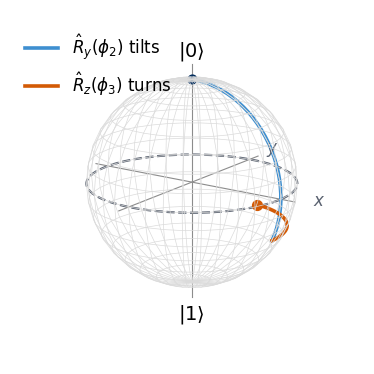

Bloch vector after each gate:
 [[ 0.     0.     1.   ]
 [ 0.     0.     1.   ]
 [ 0.909  0.    -0.416]
 [ 0.155  0.896 -0.416]]


In [4]:
def wrap(a):                                        # a rotation by a and by a + 2 pi moves the Bloch vector alike
    return (a + np.pi) % (2 * np.pi) - np.pi

def bloch_path(gates, psi0=KET0, n=30):
    """gates: list of (rz or ry, angle). Returns the continuous Bloch path and the points after each gate."""
    psi, path, ends = psi0, [np.asarray(bloch(psi0))], [np.asarray(bloch(psi0))]
    for g, a in gates:
        a_eff = wrap(float(a))
        path += [np.asarray(bloch(g(t * a_eff) @ psi)) for t in np.linspace(0, 1, n)[1:]]
        psi = g(float(a)) @ psi
        ends.append(np.asarray(bloch(psi)))
    return np.array(path), np.array(ends), psi

def draw_sphere(ax, labels=True):
    u, v = np.linspace(0, 2 * np.pi, 37), np.linspace(0, np.pi, 19)
    ax.plot_wireframe(np.outer(np.cos(u), np.sin(v)), np.outer(np.sin(u), np.sin(v)),
                      np.outer(np.ones_like(u), np.cos(v)), color="0.86", lw=0.5)
    t = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(t), np.sin(t), 0 * t, color=GRAY, lw=1.6, ls="--")          # equator
    for e in np.eye(3):
        ax.plot(*np.c_[-1.15 * e, 1.15 * e], color="0.55", lw=0.8)
    if labels:
        ax.text(0, 0, 1.22, r"$|0\rangle$", ha="center", fontsize=14)
        ax.text(0, 0, -1.38, r"$|1\rangle$", ha="center", fontsize=14)
        ax.text(1.35, 0, 0, "$x$", fontsize=12, color=GRAY); ax.text(0, 1.3, 0, "$y$", fontsize=12, color=GRAY)
    ax.set_box_aspect((1, 1, 1)); ax.set_axis_off(); ax.view_init(elev=16, azim=-55)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)

phi_demo = (0.9, 2.0, 1.4)
path, ends, _ = bloch_path([(rz, phi_demo[0]), (ry, phi_demo[1]), (rz, phi_demo[2])])
n = 29
fig = plt.figure(figsize=(4.8, 4.6))
ax = fig.add_subplot(projection="3d"); draw_sphere(ax)
ax.plot(*path[n:2 * n + 1].T, color=BLUE, lw=2.6, label=r"$\hat R_y(\phi_2)$ tilts")
ax.plot(*path[2 * n:].T, color=ORANGE, lw=2.6, label=r"$\hat R_z(\phi_3)$ turns")
ax.scatter(*ends[0], color=NAVY, s=40); ax.scatter(*ends[-1], color=ORANGE, s=50, depthshade=False)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.0, 0.98))
save(fig, "fig_lab073a_bloch_rotations"); plt.show()
print("Bloch vector after each gate:\n", np.round(ends, 3))

The state starts at the north pole. The first gate $\hat R_z(\phi_1)$ leaves the Bloch vector there, because a rotation about the vertical axis does not move a point that lies on the axis, and in the amplitudes it only multiplies $|0\rangle$ by a phase. The blue arc is the tilt by $\hat R_y(\phi_2)$ along a meridian down to the polar angle $\phi_2$, and the orange arc is the turn by $\hat R_z(\phi_3)$ along a circle of constant height. The probability of outcome 1 is set by the height alone, so here only $\phi_2$ affects it. This observation decides what a single upload of the data can do.

## 4. A single upload of the data

The simplest way to give the data to the circuit is to use them as rotation angles. The gate (5) has three angles and the data point has two components, so we pad it with a zero, $\mathbf x=(x_1,x_2,0)$. Each angle gets a trainable offset and a trainable weight, $\boldsymbol\phi=\boldsymbol\theta+\mathbf w\circ\mathbf x$, where $\circ$ is the element-wise product, $(\mathbf w\circ\mathbf x)_j=w_jx_j$. The one-layer classifier prepares
$$|\psi(\mathbf x)\rangle=\hat U(\boldsymbol\theta+\mathbf w\circ\mathbf x)|0\rangle , \tag{6}$$
and its output is the probability $P(1\,|\,\mathbf x)=|\langle1|\psi(\mathbf x)\rangle|^2$ of measuring 1. A point is assigned to class 1 when this probability exceeds one half.

We apply the three gates in turn. The first one only multiplies $|0\rangle$ by a phase,
$$\hat R_z(\phi_1)|0\rangle=e^{-i\phi_1/2}|0\rangle ,$$
the second one tilts the state,
$$\hat R_y(\phi_2)\,e^{-i\phi_1/2}|0\rangle=e^{-i\phi_1/2}\Big(\cos\frac{\phi_2}{2}|0\rangle+\sin\frac{\phi_2}{2}|1\rangle\Big),$$
and the third one multiplies the two amplitudes by phases of modulus one, which does not change their moduli. The output is therefore
$$P(1\,|\,\mathbf x)=\sin^2\frac{\phi_2}{2}=\sin^2\frac{\theta_2+w_2x_2}{2}. \tag{7}$$
The coordinate $x_1$ enters only through a common phase and drops out. The output depends on $x_2$ alone, and the decision boundary, the set of points with $P(1\,|\,\mathbf x)=1/2$, consists of horizontal lines $x_2=\text{const}$. The same argument holds for any assignment of affine functions of $\mathbf x$ to the three angles, because only the affine combination placed in $\phi_2$ reaches the probability, and the boundary is then a set of parallel straight lines.

The best such classifier for the circle is a horizontal band $|x_2|<a$ labelled as class 1. It follows from (7) with $\theta_2=\pi$ and $w_2=\pi/(2a)$, since then $P(1\,|\,\mathbf x)=\cos^2[\pi x_2/(4a)]$ exceeds one half if and only if $|x_2|<a$. We scan the half-width $a$ between $1/3$ and 1 on the training set, choose the best value and evaluate it on the test set. Below $a=1/3$ the function $\cos^2[\pi x_2/(4a)]$ exceeds one half also in further stripes inside the square, $3a<|x_2|<5a$, which only adds misclassified points.

equation (7) holds and P(1|x) does not depend on x_1


best band |x_2| < 0.58: training accuracy 0.772, test accuracy 0.756


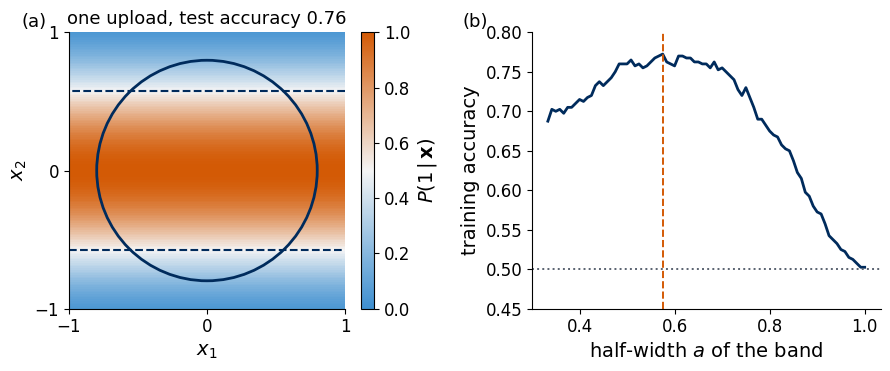

In [5]:
def p1_single(theta, w, x):                    # equation (6), one upload
    xx = jnp.array([x[0], x[1], 0.0])
    return jnp.abs((U(theta + w * xx) @ KET0)[1]) ** 2

key = jax.random.PRNGKey(731)
for i in range(5):                              # check equation (7) for random offsets, weights and points
    k1, k2, k3, key = jax.random.split(key, 4)
    th, ww, xv = jax.random.uniform(k1, (3,), minval=-3, maxval=3), jax.random.normal(k2, (3,)), jax.random.uniform(k3, (2,), minval=-1, maxval=1)
    assert abs(p1_single(th, ww, xv) - jnp.sin((th[1] + ww[1] * xv[1]) / 2) ** 2) < TOL
    assert abs(p1_single(th, ww, xv) - p1_single(th, ww, xv.at[0].set(0.37))) < TOL     # x_1 drops out
print("equation (7) holds and P(1|x) does not depend on x_1")

def band_params(a):
    return jnp.array([0.0, jnp.pi, 0.0]), jnp.array([0.0, jnp.pi / (2 * a), 0.0])

p1_single_batch = jax.vmap(p1_single, in_axes=(None, None, 0))
a_grid = np.linspace(1 / 3, 1.0, 81)                   # for a >= 1/3 the region P > 1/2 inside the square is one band
acc_band = np.array([np.mean((np.asarray(p1_single_batch(*band_params(a), Xtr)) > 0.5) == ytr) for a in a_grid])
a_best = a_grid[np.argmax(acc_band)]
acc_band_test = float(np.mean((np.asarray(p1_single_batch(*band_params(a_best), Xte)) > 0.5) == yte))
print(f"best band |x_2| < {a_best:.2f}: training accuracy {acc_band.max():.3f}, test accuracy {acc_band_test:.3f}")
RESULTS["single_upload_band"] = dict(a=float(a_best), train_acc=float(acc_band.max()), test_acc=acc_band_test)

g = np.linspace(-1, 1, 161); GRID = np.array([[u, v] for v in g for u in g])
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.9), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axs[0]
Pmap = np.asarray(p1_single_batch(*band_params(a_best), GRID)).reshape(len(g), len(g))
im = ax.pcolormesh(g, g, Pmap, cmap=PROB_CMAP, vmin=0, vmax=1, shading="auto")
ax.contour(g, g, Pmap, levels=[0.5], colors=[NAVY], linewidths=1.5, linestyles="--")
draw_circle(ax); square_axes(ax)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label(r"$P(1\,|\,\mathbf{x})$")
ax.set_title(f"one upload, test accuracy {acc_band_test:.2f}")
ax.text(-0.17, 1.02, "(a)", transform=ax.transAxes)
ax = axs[1]
ax.plot(a_grid, acc_band, color=NAVY, lw=2)
ax.axvline(a_best, color=ORANGE, ls="--", lw=1.4); ax.axhline(0.5, color=GRAY, ls=":", lw=1.4)
ax.set_xlabel("half-width $a$ of the band"); ax.set_ylabel("training accuracy"); ax.set_ylim(0.45, 0.8)
ax.text(-0.2, 1.02, "(b)", transform=ax.transAxes)
fig.tight_layout(); save(fig, "fig_lab073a_single_upload"); plt.show()

Panel (a) shows the output (7) of the best single-upload classifier as a colour map, with the boundary $P(1\,|\,\mathbf x)=1/2$ as dashed lines and the true circle in navy. Orange means a high probability of class 1. The classifier labels a horizontal band as class 1 and misses the parts of the disc above and below the band as well as the corners inside it. Panel (b) shows the training accuracy as a function of the half-width of the band, with the best value marked. About three quarters of the points are classified correctly, well above guessing and far from a useful classifier for this task.

## 5. Data re-uploading

The single upload fails because the data act on a state that sits at the north pole, where the first rotation has no effect, and because one tilt gives only one function of $\mathbf x$. Ref. [1] removes both limitations by loading the data again in every layer, each time with its own offsets and weights,
$$|\psi(\mathbf x)\rangle=\hat U(\boldsymbol\theta_L+\mathbf w_L\circ\mathbf x)\cdots\hat U(\boldsymbol\theta_2+\mathbf w_2\circ\mathbf x)\,\hat U(\boldsymbol\theta_1+\mathbf w_1\circ\mathbf x)|0\rangle,\qquad \mathbf x=(x_1,x_2,0). \tag{8}$$
Layer $\ell=1,\dots,L$ carries the offsets $\boldsymbol\theta_\ell$ and the weights $\mathbf w_\ell$, three of each, so the circuit has $6L$ trainable numbers. After the first layer the Bloch vector no longer lies on the vertical axis, so the first $\hat R_z$ of the second layer moves it, and $x_1$ now changes the probabilities. Every layer rotates the state produced by the previous one, and the output becomes a nested function of $\mathbf x$ whose complexity grows with $L$.

There is an analogy with a neural network. A neuron computes $\sigma(\mathbf w\cdot\mathbf x+b)$, an affine function of its input followed by a fixed nonlinear function $\sigma$. A layer of the circuit computes the angles $\boldsymbol\theta_\ell+\mathbf w_\ell\circ\mathbf x$, which are affine functions of the data, and the rotation acts with the trigonometric functions of (4), which are nonlinear. The qubit state plays the role of the hidden activations handed from layer to layer. Unlike the activations of a network, it holds only two complex amplitudes, and the data are fed in again at every layer.

The circuit diagram shows the structure (8). The data enter every gate from the top, and the measurement at the end returns 0 or 1.

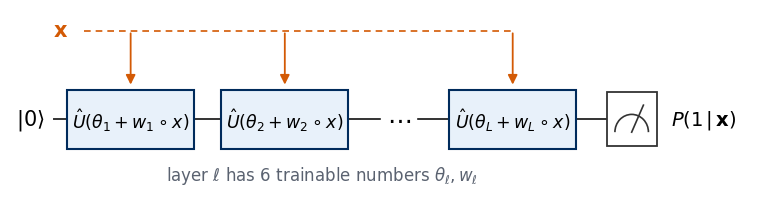

In [6]:
fig, ax = plt.subplots(figsize=(9.6, 2.4))
xs_box = [1.6, 3.9, 7.3]
labels = [r"$\hat U(\theta_1+w_1\circ x)$", r"$\hat U(\theta_2+w_2\circ x)$", r"$\hat U(\theta_L+w_L\circ x)$"]
ax.plot([0.45, 9.0], [0, 0], color="0.2", lw=1.4)
ax.text(0.1, 0, r"$|0\rangle$", ha="center", va="center", fontsize=15)
ax.plot([0.9, 7.3], [1.25, 1.25], color=ORANGE, lw=1.2, ls=(0, (4, 3)))
ax.text(0.55, 1.25, r"$\mathbf{x}$", color=ORANGE, ha="center", va="center", fontsize=15)
for xb, lab in zip(xs_box, labels):
    ax.add_patch(Rectangle((xb - 0.95, -0.42), 1.9, 0.84, facecolor="#E8F1FA", edgecolor=NAVY, lw=1.5, zorder=3))
    ax.text(xb, 0, lab, ha="center", va="center", fontsize=12.5, zorder=4)
    ax.add_patch(FancyArrowPatch((xb, 1.25), (xb, 0.45), arrowstyle="-|>", mutation_scale=14, color=ORANGE, lw=1.3))
ax.text(5.6, 0.0, r"$\cdots$", ha="center", va="center", fontsize=18, backgroundcolor="white", zorder=4)
ax.add_patch(Rectangle((8.7, -0.38), 0.75, 0.76, facecolor="white", edgecolor="0.2", lw=1.3, zorder=3))
ax.add_patch(Arc((9.075, -0.18), 0.5, 0.5, theta1=0, theta2=180, color="0.2", lw=1.2, zorder=4))
ax.plot([9.075, 9.25], [-0.18, 0.2], color="0.2", lw=1.2, zorder=4)
ax.text(10.15, 0, r"$P(1\,|\,\mathbf{x})$", ha="center", va="center", fontsize=14)
ax.text(4.45, -0.85, r"layer $\ell$ has 6 trainable numbers $\theta_\ell, w_\ell$", ha="center", fontsize=12, color=GRAY)
ax.set_xlim(-0.2, 10.9); ax.set_ylim(-1.05, 1.55); ax.axis("off")
save(fig, "fig_lab073a_circuit"); plt.show()

The code implements (8). Inside the compiled loops each gate acts element-wise on the two amplitudes, which gives the same result as the matrix product and runs faster, and Section 3 checks the two forms against each other. A loop over the layers is written with `lax.scan`, which compiles one layer and repeats it, and a second function returns the state after every layer, which we need for the Bloch-sphere pictures. The parameters are a pair of arrays, the offsets $\boldsymbol\theta$ and the weights $\mathbf w$, each of shape $(L,3)$. For $L=1$ the circuit must reproduce equation (7).

In [7]:
def pad(x):
    return jnp.array([x[0], x[1], 0.0])                              # x = (x_1, x_2, 0)

def layer_states(params, x):
    """States after layers 0, 1, ..., L of circuit (8), shape (L+1, 2)."""
    theta, w = params
    xx = pad(x)
    def layer(psi, tw):
        t, ww = tw
        psi = apply_U(psi, t + ww * xx)
        return psi, psi
    _, psis = lax.scan(layer, KET0, (theta, w))
    return jnp.concatenate([KET0[None], psis])

def psi_reup(params, x):
    return layer_states(params, x)[-1]

def p1(params, x):                                                     # P(1|x) = |<1|psi(x)>|^2
    return jnp.abs(psi_reup(params, x)[1]) ** 2

p1_batch = jax.jit(jax.vmap(p1, in_axes=(None, 0)))

th1, w1 = jnp.array([[0.4, 1.1, -0.7]]), jnp.array([[0.9, -1.3, 0.2]])
for xv in Xtr[:5]:
    assert abs(p1((th1, w1), xv) - jnp.sin((th1[0, 1] + w1[0, 1] * xv[1]) / 2) ** 2) < TOL
th3, w3 = jax.random.normal(jax.random.PRNGKey(1), (3, 3)), jax.random.normal(jax.random.PRNGKey(2), (3, 3))
xv = jnp.array(Xtr[0])
direct = U(th3[2] + w3[2] * pad(xv)) @ U(th3[1] + w3[1] * pad(xv)) @ U(th3[0] + w3[0] * pad(xv)) @ KET0
assert jnp.allclose(psi_reup((th3, w3), xv), direct, atol=TOL)
x_a, x_b = jnp.array([0.2, 0.5]), jnp.array([-0.6, 0.5])           # same x_2, different x_1
print(f"L = 1: P(1|x) at {np.asarray(x_a)} and {np.asarray(x_b)}: {float(p1((th1, w1), x_a)):.4f}, {float(p1((th1, w1), x_b)):.4f}")
print(f"L = 3: P(1|x) at {np.asarray(x_a)} and {np.asarray(x_b)}: {float(p1((th3, w3), x_a)):.4f}, {float(p1((th3, w3), x_b)):.4f}")

L = 1: P(1|x) at [0.2 0.5] and [-0.6  0.5]: 0.0498, 0.0498
L = 3: P(1|x) at [0.2 0.5] and [-0.6  0.5]: 0.5276, 0.6406


With one layer the two points, which share $x_2$, have the same output, as equation (7) demands. With three layers and random parameters their outputs differ, so the first coordinate now reaches the measurement.

## 6. Label states, loss and prediction

The circuit must turn the output state into a class. We assign to each class $c$ a *label state* $|\psi_c\rangle$, and the label states of different classes should lie as far apart on the Bloch sphere as possible, so that final states near different label states are easy to tell apart. The overlap of two states with Bloch vectors $\mathbf r$ and $\mathbf r'$ is
$$|\langle\psi|\psi'\rangle|^2=\frac{1+\mathbf r\cdot\mathbf r'}{2}, \tag{9}$$
which vanishes only for opposite Bloch vectors. Two classes use the poles $|0\rangle$ and $|1\rangle$, with fidelity 0. A qubit has no third state orthogonal to both poles, so three classes use three Bloch vectors $120^\circ$ apart on a great circle, whose scalar product $-1/2$ gives by (9) the pairwise fidelity $1/4$. Four classes use the corners of a regular tetrahedron inscribed in the sphere, with the scalar product $-1/3$ and the pairwise fidelity $1/3$, the smallest possible for four states of a qubit.

The fidelity of the final state with the label state of class $c$ decides the class,
$$F_c(\mathbf x)=|\langle\psi_c|\psi(\mathbf x)\rangle|^2,\qquad \hat y(\mathbf x)=\arg\max_c F_c(\mathbf x), \tag{10}$$
so a point is assigned the class whose label state lies closest to its final state. The hat on $\hat y$ marks a prediction, the usual statistics notation, and it is the only hat in this notebook that does not denote an operator. On a device $F_c(\mathbf x)$ would be estimated as the frequency of finding $|\psi_c\rangle$ in repeated measurements at the same input. Training brings the state of each training point close to the label state of its own class by minimising the average infidelity over the training set,
$$\mathcal L(\boldsymbol\theta,\mathbf w)=\frac1M\sum_{m=1}^{M}\big[1-F_{y_m}(\mathbf x_m)\big], \tag{11}$$
where $\boldsymbol\theta$ and $\mathbf w$ collect the offsets and weights of all layers.

For the two classes of the circle task the label states are $|0\rangle$ for class 0 and $|1\rangle$ for class 1. The fidelity with $|1\rangle$ is the probability of measuring 1,
$$P(1\,|\,\mathbf x)=|\langle1|\psi(\mathbf x)\rangle|^2=\frac{1-r_z(\mathbf x)}{2}, \tag{12}$$
where $r_z(\mathbf x)$ is the height of the Bloch vector of $|\psi(\mathbf x)\rangle$, and the fidelity with $|0\rangle$ is $1-P(1\,|\,\mathbf x)$. The largest-fidelity rule (10) therefore compares one probability with one half,
$$\hat y(\mathbf x)=\begin{cases}1, & P(1\,|\,\mathbf x)>\frac12,\\ 0, & \text{otherwise},\end{cases} \tag{13}$$
and the loss (11) becomes
$$\mathcal L(\boldsymbol\theta,\mathbf w)=\frac1M\sum_{m=1}^{M}\Big[\underbrace{y_m\big(1-P(1\,|\,\mathbf x_m)\big)}_{\text{class 1 should reach }|1\rangle}+\underbrace{(1-y_m)\,P(1\,|\,\mathbf x_m)}_{\text{class 0 should stay near }|0\rangle}\Big]. \tag{14}$$

Equation (12) gives a geometric picture of the classifier. The circuit is a learned map from the square onto the Bloch sphere, prediction (13) assigns class 1 to the southern hemisphere, and the decision boundary in the square is the set of points mapped onto the equator. Training has to move the points of class 1 towards the south pole and keep the points of class 0 near the north pole.

We construct the label states for two, three and four classes and check their pairwise fidelities against (9). We then define the loss (14) and the accuracy of prediction (13) for the circle task.

In [8]:
def ket_from_angles(vartheta, varphi):              # cos(vartheta/2)|0> + e^{i varphi} sin(vartheta/2)|1>
    return jnp.array([np.cos(vartheta / 2), np.exp(1j * varphi) * np.sin(vartheta / 2)], dtype=CDTYPE)

LABELS2 = jnp.stack([ket_from_angles(0.0, 0.0), ket_from_angles(np.pi, 0.0)])                  # poles
LABELS3 = jnp.stack([ket_from_angles(2 * np.pi * c / 3, 0.0) for c in range(3)])                 # x-z great circle
vt = np.arccos(-1 / 3)                                                                           # lower corners
LABELS4 = jnp.stack([ket_from_angles(0.0, 0.0)] + [ket_from_angles(vt, 2 * np.pi * k / 3) for k in range(3)])

for name, lab, f_pair in (("2 classes", LABELS2, 0.0), ("3 classes", LABELS3, 0.25), ("4 classes", LABELS4, 1 / 3)):
    F = np.abs(np.asarray(lab.conj() @ lab.T)) ** 2
    R = np.asarray(jax.vmap(bloch)(lab))
    assert np.allclose(F[~np.eye(len(lab), dtype=bool)], f_pair, atol=TOL)
    assert np.allclose(F, (1 + R @ R.T) / 2, atol=TOL)                                           # equation (9)
    print(f"{name}: pairwise fidelity {f_pair:.4f}, Bloch vectors\n", np.round(R, 4))

2 classes: pairwise fidelity 0.0000, Bloch vectors
 [[ 0.  0.  1.]
 [ 0.  0. -1.]]


3 classes: pairwise fidelity 0.2500, Bloch vectors
 [[ 0.     0.     1.   ]
 [ 0.866  0.    -0.5  ]
 [-0.866  0.    -0.5  ]]


4 classes: pairwise fidelity 0.3333, Bloch vectors
 [[ 0.      0.      1.    ]
 [ 0.9428  0.     -0.3333]
 [-0.4714  0.8165 -0.3333]
 [-0.4714 -0.8165 -0.3333]]


In [9]:
def loss_infidelity(params, X, y):                     # equation (14)
    q = jax.vmap(p1, in_axes=(None, 0))(params, X)
    return jnp.mean(y * (1 - q) + (1 - y) * q)

def accuracy(p1_values, y):                             # prediction (13) compared with the labels
    return float(np.mean((np.asarray(p1_values) > 0.5) == y))

for xv in Xtr[:5]:                                      # equation (12)
    psi = psi_reup((th3, w3), xv)
    assert abs(jnp.abs(psi[1]) ** 2 - (1 - bloch(psi)[2]) / 2) < TOL
print(f"random L = 3 circuit: loss {float(loss_infidelity((th3, w3), Xtr, ytr)):.3f},"
      f" training accuracy {accuracy(p1_batch((th3, w3), Xtr), ytr):.3f}")

random L = 3 circuit: loss 0.494, training accuracy 0.535


An untrained circuit with random parameters gives a loss near one half and an accuracy near guessing, because its outputs are unrelated to the labels.

## 7. Training with exact gradients and Adam

The loss (14) is a smooth function of the $6L$ parameters, and we minimise it by gradient descent. In the simulation `jax.grad` returns the exact gradient by automatic differentiation of the code that computes the loss. On a device each angle $\phi_{\ell,j}=\theta_{\ell,j}+w_{\ell,j}x_j$ enters a single rotation. The derivative with respect to the offset $\theta_{\ell,j}$ then follows from the parameter-shift rule with two circuits per angle and training point, and the chain rule gives the derivative with respect to the weight as $x_j$ times the same quantity.

We use the Adam optimiser [4], a gradient method that scales the step of each parameter by running averages of its gradient and of the squared gradient. Its update takes a few lines in the code cell. The offsets start uniformly in $[-\pi,\pi]$ and the weights from a standard normal distribution, and we run 1500 steps with the step size 0.03. The loss of a circuit has many local minima, so we train from four random starts and keep the one with the lowest training loss. The test set plays no role in this choice. The training loop is compiled with `lax.scan`, and `jax.vmap` trains the four starts in parallel. We first train a circuit with $L=4$ layers.

L = 4, 4 starts trained in 6.7 s (including compilation)
final training loss of each start: [0.216 0.216 0.261 0.242]


best start: training accuracy 0.873, test accuracy 0.866


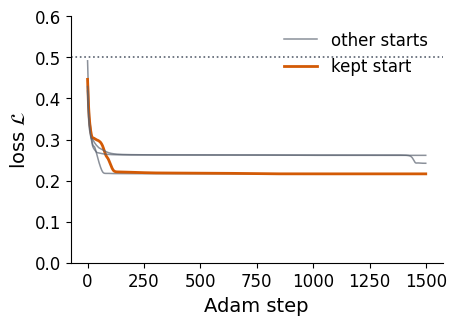

In [10]:
STEPS, LR, STARTS = 1500, 0.03, 4

def adam_train(loss_fn, params0, steps, lr, b1=0.9, b2=0.999, eps=1e-8):
    """Adam [4] on a pytree of parameters. Returns the final parameters and the loss before every step."""
    tm = jax.tree_util.tree_map
    value_and_grad = jax.value_and_grad(loss_fn)
    def step(carry, t):
        p, m, v = carry
        val, g = value_and_grad(p)
        m = tm(lambda m_, g_: b1 * m_ + (1 - b1) * g_, m, g)              # running mean of the gradient
        v = tm(lambda v_, g_: b2 * v_ + (1 - b2) * g_ ** 2, v, g)         # running mean of its square
        p = tm(lambda p_, m_, v_: p_ - lr * (m_ / (1 - b1 ** t)) / (jnp.sqrt(v_ / (1 - b2 ** t)) + eps), p, m, v)
        return (p, m, v), val
    zeros = tm(jnp.zeros_like, params0)
    (p, _, _), losses = lax.scan(step, (params0, zeros, zeros), jnp.arange(1, steps + 1, dtype=jnp.float64))
    return p, losses

def make_trainer(loss_fn, steps=STEPS, lr=LR):
    """loss_fn(params, X, y). Returns a compiled function that trains a batch of starts in parallel."""
    def one(p0, X, y):
        return adam_train(lambda p: loss_fn(p, X, y), p0, steps, lr)
    return jax.jit(jax.vmap(one, in_axes=(0, None, None)))

def initial_params(L, seeds, shape=(3,), w_std=1.0):
    th, w = [], []
    for s in seeds:                                  # offsets uniform in [-pi, pi], weights normal with width w_std
        k = np.random.default_rng(s)
        th.append(k.uniform(-np.pi, np.pi, (L,) + shape)); w.append(k.normal(0, w_std, (L,) + shape))
    return jnp.array(np.stack(th)), jnp.array(np.stack(w))

train_circle = make_trainer(loss_infidelity)
trained = {}                                         # L -> (best params, loss curves of all starts, final losses)

def fit_circle(L):
    if L not in trained:
        P, curves = train_circle(initial_params(L, [100 * L + s for s in range(STARTS)]), Xtr, ytr)
        final = np.array([float(loss_infidelity((P[0][i], P[1][i]), Xtr, ytr)) for i in range(STARTS)])
        b = int(np.argmin(final))
        trained[L] = ((P[0][b], P[1][b]), np.asarray(curves), final)
    return trained[L]

t0 = time.perf_counter()
params4, curves4, final4 = fit_circle(4)
print(f"L = 4, {STARTS} starts trained in {time.perf_counter() - t0:.1f} s (including compilation)")
print("final training loss of each start:", np.round(final4, 3))
print(f"best start: training accuracy {accuracy(p1_batch(params4, Xtr), ytr):.3f}, test accuracy {accuracy(p1_batch(params4, Xte), yte):.3f}")

fig, ax = plt.subplots(figsize=(4.8, 3.2))
for i, c in enumerate(curves4):
    best_i = i == int(np.argmin(final4))
    ax.plot(c, color=ORANGE if best_i else GRAY, lw=2 if best_i else 1.1, alpha=1 if best_i else 0.7,
            label="kept start" if best_i else ("other starts" if i == (1 if np.argmin(final4) == 0 else 0) else None))
ax.axhline(0.5, color=GRAY, ls=":", lw=1.2)
ax.set_xlabel("Adam step"); ax.set_ylabel(r"loss $\mathcal{L}$"); ax.set_ylim(0, 0.6)
ax.legend(frameon=False, loc="upper right")
save(fig, "fig_lab073a_training_L4"); plt.show()

The loss falls fast in the first hundred steps and then slowly, and the starts end at different values because they settle in different local minima. The kept start (orange) reaches the lowest training loss. The training and test accuracies printed above are close to each other, so the four-layer circuit generalises from the training points to unseen points.

## 8. The classifier on the Bloch sphere

The trained circuit maps every data point to a point on the Bloch sphere, and we can follow this map layer by layer. We take three test points deep inside the disc ($r<0.4$, class 1) and three in the corners of the square ($r>1.1$, class 0), where $r=|\mathbf x|$ is the distance from the origin, and draw the path of their Bloch vectors through the $3L=12$ rotations of the trained $L=4$ circuit. Points close to the boundary would end near the equator, so we choose points far from it to make the end points easy to see. The markers show the state after each layer.

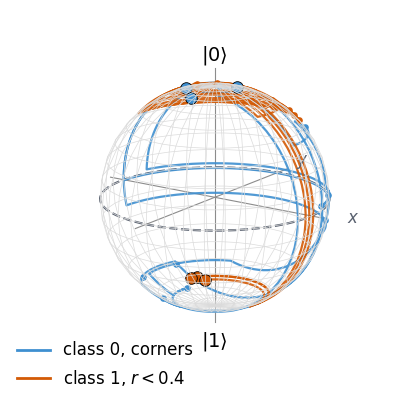

class 0 points: final P(1|x) = [0.027 0.016 0.009]
class 1 points: final P(1|x) = [0.95  0.94  0.939]


In [11]:
def circuit_path(params, x, n=30):
    theta, w = (np.asarray(p) for p in params)
    xx = np.array([x[0], x[1], 0.0])
    gates = []
    for l in range(len(theta)):
        phi = theta[l] + w[l] * xx
        gates += [(rz, phi[0]), (ry, phi[1]), (rz, phi[2])]
    path, ends, psi = bloch_path(gates, n=n)
    return path, ends[::3], psi                      # every third gate ends a layer

rad = np.sqrt((Xte ** 2).sum(1))
sel1 = np.where(rad < 0.4)[0][:3]
sel0 = np.where(rad > 1.1)[0][:3]
fig = plt.figure(figsize=(5.2, 5.0))
ax = fig.add_subplot(projection="3d"); draw_sphere(ax)
for idx, col in [(i, BLUE) for i in sel0] + [(i, ORANGE) for i in sel1]:
    path, lay, psi = circuit_path(params4, Xte[idx])
    ax.plot(*path.T, color=col, lw=1.6, alpha=0.9)
    ax.scatter(*lay[1:-1].T, color=col, s=14, depthshade=False)
    ax.scatter(*lay[-1], color=col, s=70, edgecolor="k", linewidth=0.6, depthshade=False)
    assert np.allclose(lay[-1], np.asarray(bloch(psi_reup(params4, Xte[idx]))), atol=1e-9)
ax.plot([], [], color=BLUE, lw=2, label=r"class 0, corners"); ax.plot([], [], color=ORANGE, lw=2, label=r"class 1, $r<0.4$")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(-0.04, -0.02))
save(fig, "fig_lab073a_bloch_trajectories"); plt.show()
for name, s in (("class 0", sel0), ("class 1", sel1)):
    print(name, "points: final P(1|x) =", np.round(np.asarray(p1_batch(params4, Xte[s])), 3))

All paths start at the north pole. They wander over the sphere in the intermediate layers, and the large markers show where they end. The blue paths of the corner points return to the neighbourhood of the north pole, the orange paths of the points inside the disc end near the south pole, and the printed probabilities confirm this. Points of the same class can follow different routes and still reach the same pole, because only the final height enters the prediction.

The second picture shows where all test points end. We plot the final Bloch vectors of 600 test points coloured by their true class. Points near the equator have $P(1\,|\,\mathbf x)$ close to one half, so they lie close to the decision boundary in the square, and a point on the wrong hemisphere is misclassified.

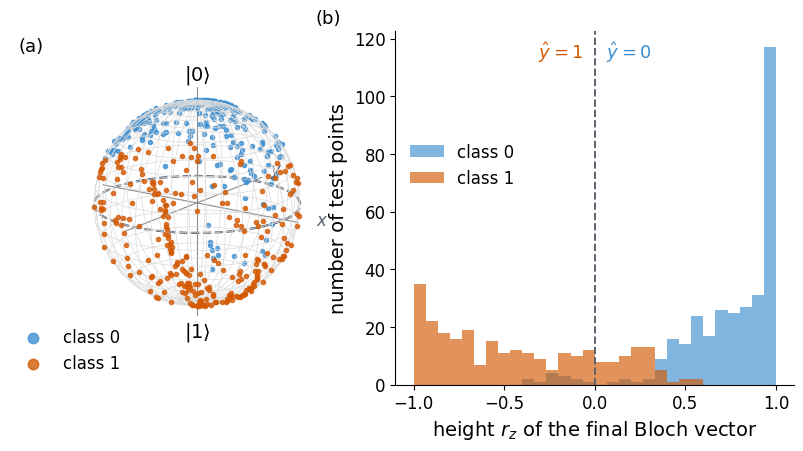

fraction of the 600 points on the correct hemisphere: 0.875


In [12]:
sub = np.random.default_rng(8).choice(len(Xte), 600, replace=False)
R_end = np.asarray(jax.vmap(lambda x: bloch(psi_reup(params4, x)))(jnp.array(Xte[sub])))
fig = plt.figure(figsize=(10.0, 4.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.15], wspace=0.08)
ax = fig.add_subplot(gs[0], projection="3d"); draw_sphere(ax)
for c, col in ((0, BLUE), (1, ORANGE)):
    m = yte[sub] == c
    ax.scatter(*R_end[m].T, color=col, s=9, alpha=0.8, depthshade=False, label=f"class {c}")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(-0.05, -0.02), markerscale=2.5)
ax.text2D(0.0, 0.95, "(a)", transform=ax.transAxes)
ax = fig.add_subplot(gs[1])
bins = np.linspace(-1, 1, 31)
ax.hist(R_end[yte[sub] == 0, 2], bins=bins, color=BLUE, alpha=0.65, label="class 0")
ax.hist(R_end[yte[sub] == 1, 2], bins=bins, color=ORANGE, alpha=0.65, label="class 1")
ax.axvline(0, color=GRAY, ls="--", lw=1.4)
ax.set_xlabel(r"height $r_z$ of the final Bloch vector"); ax.set_ylabel("number of test points")
ytop = ax.get_ylim()[1]
ax.text(-0.06, ytop * 0.92, r"$\hat y=1$", color=ORANGE, ha="right"); ax.text(0.06, ytop * 0.92, r"$\hat y=0$", color=BLUE, ha="left")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(0.0, 0.62))
ax.text(-0.2, 1.02, "(b)", transform=ax.transAxes)
save(fig, "fig_lab073a_bloch_endpoints"); plt.show()
print(f"fraction of the 600 points on the correct hemisphere: {np.mean((R_end[:, 2] < 0) == yte[sub]):.3f}")

In panel (a) the two classes gather around opposite poles, with a band of points of both colours near the equator. Panel (b) counts the heights $r_z$ of the final Bloch vectors. Most points of class 1 lie at negative heights, where the prediction is $\hat y=1$, most points of class 0 at positive heights, and the overlap near $r_z=0$ consists of the points close to the circle, where the four-layer circuit is uncertain or wrong.

## 9. Expressive power and the Fourier series

The class of a point is decided by the function $f(\mathbf x)=P(1\,|\,\mathbf x)$ through the rule $f(\mathbf x)>1/2$, so the decision boundary is the level set $f(\mathbf x)=1/2$. A model can draw only those boundaries that are level sets of functions it can produce, and this family of functions is its *expressive power*. For a neural network with enough neurons the universal approximation theorem guarantees that the family contains every continuous function. For a re-uploading circuit the family follows from Fourier analysis [3]. The frequencies of $f$ set how fast it can change with $\mathbf x$. Low frequencies give smooth functions with simple boundaries, and high frequencies give rapid changes, curved boundaries and several separate class regions.

To see why more uploads give more frequencies, we take a single real input $x$ loaded by the encoding gate $\hat S(x)=e^{-ix\hat Z/2}=\hat R_z(x)$, repeated $L$ times and interleaved with trainable gates $\hat W_0,\dots,\hat W_L$, each of the general form (5),
$$|\psi(x)\rangle=\hat W_L\,\hat S(x)\,\hat W_{L-1}\cdots\hat W_1\,\hat S(x)\,\hat W_0|0\rangle . \tag{17}$$
The model output is the expectation value $f(x)=\langle\psi(x)|\hat O|\psi(x)\rangle$ of a measured observable $\hat O$, here $\hat O=\hat Z$, so that $f(x)=1-2P(1\,|\,x)$.

The encoding gate is diagonal, $\hat S(x)|j\rangle=e^{-is_jx/2}|j\rangle$ with $s_0=+1$ for $|0\rangle$ and $s_1=-1$ for $|1\rangle$. We insert the identity $\sum_{j}|j\rangle\langle j|$ in front of every encoding gate and write the amplitude of the basis state $|i\rangle$ as a sum over all sequences $j_1,\dots,j_L$ of basis states visited by the encoding gates,
$$\langle i|\psi(x)\rangle=\sum_{j_1,\dots,j_L}\langle i|\hat W_L|j_L\rangle\,e^{-is_{j_L}x/2}\,\langle j_L|\hat W_{L-1}|j_{L-1}\rangle\cdots e^{-is_{j_1}x/2}\,\langle j_1|\hat W_0|0\rangle . \tag{18}$$
Each term depends on $x$ only through the product of the phases, $e^{-ikx/2}$ with $k=s_{j_1}+\dots+s_{j_L}$. A sum of $L$ signs $\pm1$ takes the values $k\in\{-L,-L+2,\dots,L\}$, and collecting the terms with equal $k$ gives
$$\langle i|\psi(x)\rangle=\sum_{k}a_{i,k}\,e^{-ikx/2}, \tag{19}$$
where the coefficients $a_{i,k}$ depend only on the trainable gates. The expectation value multiplies an amplitude by a conjugate amplitude,
$$f(x)=\sum_{i,i'}\langle\psi(x)|i\rangle\,O_{ii'}\,\langle i'|\psi(x)\rangle=\sum_{k,k'}\Big[\sum_{i,i'}a^*_{i,k}O_{ii'}a_{i',k'}\Big]e^{i(k-k')x/2}, \tag{20}$$
with $O_{ii'}=\langle i|\hat O|i'\rangle$. The difference $k-k'$ is even and lies between $-2L$ and $2L$, so $\omega=(k-k')/2$ is an integer between $-L$ and $L$, and
$$f(x)=\sum_{\omega=-L}^{L}c_\omega\,e^{i\omega x},\qquad c_{-\omega}=c_\omega^* . \tag{21}$$
The relation between $c_\omega$ and $c_{-\omega}$ makes $f$ real, as an expectation value of a Hermitian operator must be. The model is a trigonometric polynomial of degree $L$. The encoding fixes which frequencies can appear, the integers up to $L$, and the trainable gates set the coefficients $c_\omega$. A trainable weight $w$ in front of the data, $\hat S(wx)$, rescales the frequencies to $w\omega$.

The two-dimensional classifier (8) follows the same rule. The coordinate $x_1$ enters through $\hat R_z$, and $x_2$ through $\hat R_y$, which has the same eigenvalues $e^{\mp i\alpha/2}$ in its own eigenbasis. The output $P(1\,|\,\mathbf x)$ is therefore a trigonometric polynomial in $x_1$ and $x_2$ whose frequencies are sums of at most $L$ weights, and more layers bring higher frequencies and more detailed boundaries.

We test the counting on a target with the frequencies 1, 2 and 3,
$$g(x)=0.05+0.35\cos x+0.25\sin 2x-0.3\cos3x,\qquad x\in[-\pi,\pi], \tag{22}$$
and fit the model (17) with $L=1,2,3$ to 60 equally spaced samples of $g$. The model has $3(L+1)$ angles, the loss is the mean squared error between $f$ and $g$, and Adam runs 3000 steps with the step size 0.05 from six random starts per $L$.

L = 1:  6 angles, best mean squared error 7.64e-02


L = 2:  9 angles, best mean squared error 4.56e-02


L = 3: 12 angles, best mean squared error 3.58e-31
trained in 5.4 s


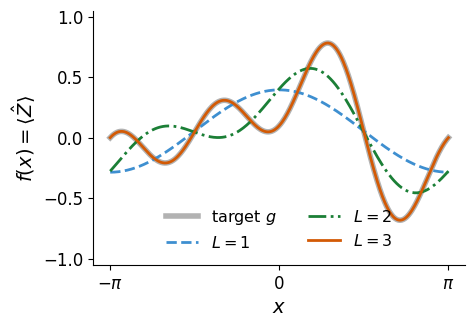

In [13]:
def g_target(x):                                    # equation (22)
    return 0.05 + 0.35 * np.cos(x) + 0.25 * np.sin(2 * x) - 0.3 * np.cos(3 * x)

def f_fourier(W, x):                                 # equation (17) with M = Z, W has shape (L+1, 3)
    def layer(psi, w_l):
        psi = jnp.stack([psi[0] * jnp.exp(-0.5j * x), psi[1] * jnp.exp(0.5j * x)])   # S(x) = R_z(x)
        return apply_U(psi, w_l), None
    psi, _ = lax.scan(layer, apply_U(KET0, W[0]), W[1:])
    return jnp.abs(psi[0]) ** 2 - jnp.abs(psi[1]) ** 2

x_fit = np.linspace(-np.pi, np.pi, 60)
def mse_loss(W, X, Y):
    return jnp.mean((jax.vmap(f_fourier, in_axes=(None, 0))(W, X) - Y) ** 2)
train_fourier = make_trainer(mse_loss, steps=3000, lr=0.05)

fits, mse = {}, {}
t0 = time.perf_counter()
for L in (1, 2, 3):
    W0 = jnp.array(np.stack([np.random.default_rng(s).uniform(-np.pi, np.pi, (L + 1, 3)) for s in range(6)]))
    W, _ = train_fourier(W0, x_fit, g_target(x_fit))
    losses = np.array([float(mse_loss(W[i], x_fit, g_target(x_fit))) for i in range(6)])
    fits[L], mse[L] = W[int(np.argmin(losses))], float(losses.min())
    print(f"L = {L}: {3 * (L + 1):2d} angles, best mean squared error {mse[L]:.2e}")
print(f"trained in {time.perf_counter() - t0:.1f} s")
RESULTS["fourier_mse"] = {L: mse[L] for L in mse}

f_batch = jax.jit(jax.vmap(f_fourier, in_axes=(None, 0)))
xf = np.linspace(-np.pi, np.pi, 400)
fig, ax = plt.subplots(figsize=(4.8, 3.3))
ax.plot(xf, g_target(xf), color="black", lw=4, alpha=0.3, label="target $g$")
for L, col, ls in [(1, BLUE, "--"), (2, GREEN, "-."), (3, ORANGE, "-")]:
    ax.plot(xf, np.asarray(f_batch(fits[L], xf)), color=col, ls=ls, lw=2, label=f"$L={L}$")
ax.set_xlabel("$x$"); ax.set_ylabel(r"$f(x)=\langle\hat Z\rangle$")
ax.set_xticks([-np.pi, 0, np.pi]); ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"]); ax.set_ylim(-1.05, 1.05)
ax.legend(frameon=False, ncol=2, loc="lower center", fontsize=11.5)
save(fig, "fig_lab073a_fourier_fit"); plt.show()

The grey band is the target, and the coloured lines are the best fits. With one upload the model contains only the frequency 1 and follows the slow trend of the target. With two uploads it adds the frequency 2 and still misses the fast oscillation. With three uploads the fit lies on top of the target, and the printed mean squared error drops to rounding error.

To compare the frequency content directly, we sample each trained model on $K=64$ equally spaced points $x_n=-\pi+2\pi n/K$ and compute $c_\omega=\frac1K\sum_n f(x_n)e^{-i\omega x_n}$ with the fast Fourier transform. For a trigonometric polynomial of degree below $K/2$ this discrete sum returns the coefficients of (21) without error. The target (22) has $|c_0|=0.05$, $|c_1|=0.175$, $|c_2|=0.125$ and $|c_3|=0.15$, half the amplitudes in (22) for $\omega\neq0$ because $\cos\omega x=(e^{i\omega x}+e^{-i\omega x})/2$.

L = 1: |c_omega| for omega = 0..4: [0.0548 0.1702 0.     0.     0.    ]   max |c_omega| above L: 5.9e-17
L = 2: |c_omega| for omega = 0..4: [0.0547 0.1703 0.1251 0.     0.    ]   max |c_omega| above L: 6.1e-17
L = 3: |c_omega| for omega = 0..4: [0.05  0.175 0.125 0.15  0.   ]   max |c_omega| above L: 7.2e-17


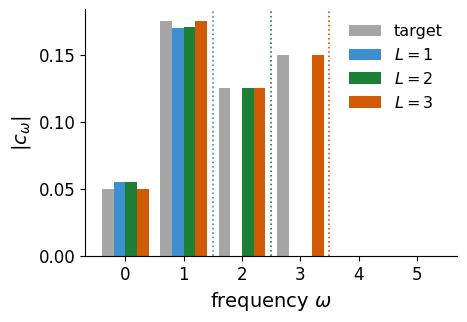

In [14]:
K = 64
x_k = -np.pi + 2 * np.pi * np.arange(K) / K
def spectrum(values):
    # c_omega = (1/K) sum_n f(x_n) exp(-i omega x_n); the shift of the grid by -pi gives the factor (-1)^omega
    return np.fft.fft(values)[: K // 2] / K * (-1.0) ** np.arange(K // 2)

c_target = spectrum(g_target(x_k))
assert np.allclose(np.abs(c_target[:4]), [0.05, 0.175, 0.125, 0.15], atol=TOL)
c_model = {L: spectrum(np.asarray(f_batch(fits[L], x_k))) for L in fits}
for L in fits:
    above = np.abs(c_model[L][L + 1:]).max()
    assert above < 1e-12                                       # no frequency above L, equation (21)
    print(f"L = {L}: |c_omega| for omega = 0..4:", np.round(np.abs(c_model[L][:5]), 4), f"  max |c_omega| above L: {above:.1e}")
RESULTS["fourier_coefficients"] = {L: np.abs(c_model[L][:5]).tolist() for L in fits}

om = np.arange(6)
fig, ax = plt.subplots(figsize=(4.8, 3.2))
wbar = 0.2
ax.bar(om - 1.5 * wbar, np.abs(c_target[:6]), wbar, color="0.65", label="target")
for j, (L, col) in enumerate([(1, BLUE), (2, GREEN), (3, ORANGE)]):
    ax.bar(om + (j - 0.5) * wbar, np.abs(c_model[L][:6]), wbar, color=col, label=f"$L={L}$")
for L, col in [(1, BLUE), (2, GREEN), (3, ORANGE)]:
    ax.axvline(L + 0.5, color=col, ls=":", lw=1.2)
ax.set_xlabel(r"frequency $\omega$"); ax.set_ylabel(r"$|c_\omega|$"); ax.set_xticks(om)
ax.legend(frameon=False, loc="upper right", fontsize=11.5)
save(fig, "fig_lab073a_fourier_spectrum"); plt.show()

The grey bars are the target coefficients and the coloured bars those of the trained models, with dotted lines at $\omega=L+1/2$. Every model has vanishing coefficients beyond its own $L$, to rounding error, as equation (21) predicts. The models with $L=1$ and $L=2$ cannot produce the frequency 3, so they adjust their lower coefficients to the best compromise, whereas the $L=3$ model reproduces all four target coefficients. The number of uploads sets the frequency content of the model, and the data re-uploading classifier gains its expressive power from this growth of the spectrum.

The classifier compares the Fourier series with one half, so the class regions are the intervals in which the curve lies above or below this level. We convert the fitted models of $L=1$ and $L=3$ into probabilities $P(1\,|\,x)=(1-f(x))/2$ and colour the input axis by the predicted class. A single frequency crosses one half at most twice per period, whereas the frequencies up to 3 give more crossings and more class intervals.

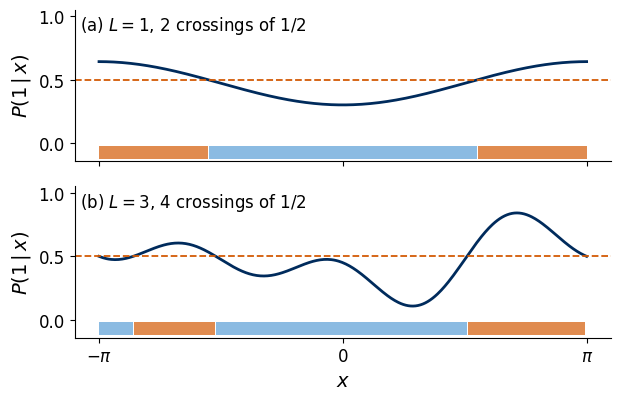

In [15]:
fig, axs = plt.subplots(2, 1, figsize=(6.4, 4.2), sharex=True)
for ax, L, lab in ((axs[0], 1, "(a)"), (axs[1], 3, "(b)")):
    pf = (1 - np.asarray(f_batch(fits[L], xf))) / 2                    # P(1|x) = (1 - <Z>)/2
    above = pf > 0.5
    ax.fill_between(xf, -0.12, -0.02, where=above, color=ORANGE, alpha=0.7, step="mid", lw=0)
    ax.fill_between(xf, -0.12, -0.02, where=~above, color=BLUE, alpha=0.6, step="mid", lw=0)
    ax.plot(xf, pf, color=NAVY, lw=2)
    ax.axhline(0.5, color=ORANGE, ls="--", lw=1.3)
    ax.set_ylim(-0.14, 1.05); ax.set_ylabel(r"$P(1\,|\,x)$")
    crossings = int(np.sum(above[1:] != above[:-1]))
    ax.text(0.01, 0.97, f"{lab} $L={L}$, {crossings} crossings of 1/2", transform=ax.transAxes, va="top", fontsize=12)
axs[1].set_xlabel("$x$"); axs[1].set_xticks([-np.pi, 0, np.pi]); axs[1].set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
fig.tight_layout(); save(fig, "fig_lab073a_fourier_threshold"); plt.show()

Orange strips mark the inputs with $P(1\,|\,x)>1/2$, predicted as class 1, and blue strips class 0. The one-upload model splits the axis into two intervals, and the three-upload model into more.

The same counting decides how general a re-uploading classifier can be. For one input variable a single qubit with enough layers can express every Fourier series of the form (21) and therefore approximate any square-integrable function [5]. For several input variables the number of Fourier terms grows exponentially with the number of variables, whereas the number of parameters of a pure single-qubit model grows only linearly with the number of layers, so it cannot express every function of several variables [5]. Trainable weights on the data, such as the weights $\mathbf w_\ell$ of circuit (8), restore universality [2], partly because these weights are a classical part of the model.

## 10. Accuracy against the number of layers

We now train the circle classifier with $L=1,\dots,6$ layers, four starts each, and keep for every $L$ the start with the lowest training loss. The cell compiles the training loop once per $L$ and runs in well under a minute. The result for $L=4$ comes from Section 7.

L = 1:  6 parameters, training loss 0.300, training accuracy 0.750, test accuracy 0.731


L = 2: 12 parameters, training loss 0.272, training accuracy 0.787, test accuracy 0.793


L = 3: 18 parameters, training loss 0.221, training accuracy 0.880, test accuracy 0.873
L = 4: 24 parameters, training loss 0.216, training accuracy 0.873, test accuracy 0.866


L = 5: 30 parameters, training loss 0.173, training accuracy 0.948, test accuracy 0.929


L = 6: 36 parameters, training loss 0.140, training accuracy 0.958, test accuracy 0.941
52.1 s


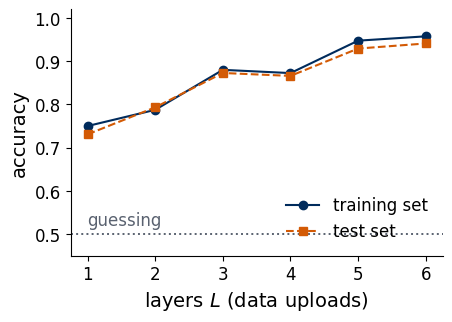

In [16]:
LS = [1, 2, 3, 4, 5, 6]
acc_tr, acc_te = {}, {}
t0 = time.perf_counter()
for L in LS:
    P, _, final = fit_circle(L)
    acc_tr[L], acc_te[L] = accuracy(p1_batch(P, Xtr), ytr), accuracy(p1_batch(P, Xte), yte)
    print(f"L = {L}: {6 * L:2d} parameters, training loss {final.min():.3f},"
          f" training accuracy {acc_tr[L]:.3f}, test accuracy {acc_te[L]:.3f}")
print(f"{time.perf_counter() - t0:.1f} s")
RESULTS["circle"] = {L: dict(params=6 * L, train_loss=float(trained[L][2].min()), train_acc=acc_tr[L], test_acc=acc_te[L]) for L in LS}

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.plot(LS, [acc_tr[L] for L in LS], "o-", color=NAVY, label="training set")
ax.plot(LS, [acc_te[L] for L in LS], "s--", color=ORANGE, label="test set")
ax.axhline(0.5, color=GRAY, ls=":", lw=1.4); ax.text(1, 0.52, "guessing", color=GRAY, ha="left", fontsize=12)
ax.set_xlabel("layers $L$ (data uploads)"); ax.set_ylabel("accuracy"); ax.set_ylim(0.45, 1.02)
ax.legend(frameon=False, loc="lower right")
save(fig, "fig_lab073a_accuracy_vs_L"); plt.show()

The navy line is the training accuracy and the orange line the test accuracy. Both rise with the number of layers, from the straight band at $L=1$, which comes close to the best band of Section 4, towards a nearly correct circle at $L=6$. The two curves stay close, so the extra parameters improve the boundary without overfitting the 400 training points. The rise is not perfectly monotonic, because each $L$ is trained from only four starts and a deeper circuit can end in a poorer local minimum. The decision maps show how the boundary changes with $L$.

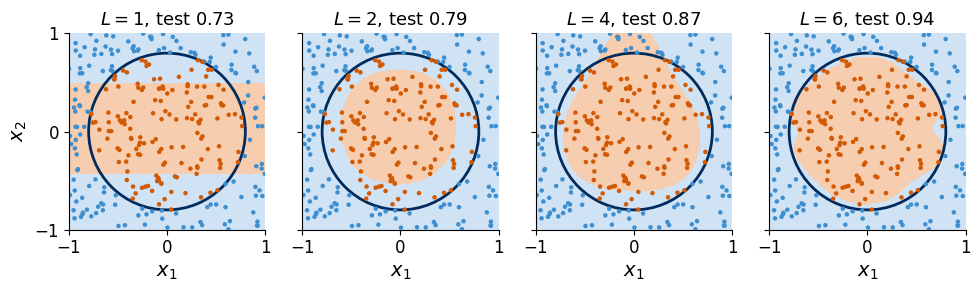

In [17]:
show_L = [1, 2, 4, 6]
pts = np.random.default_rng(10).choice(len(Xte), 300, replace=False)
fig, axs = plt.subplots(1, 4, figsize=(10.0, 2.95))
for ax, L in zip(axs, show_L):
    Z = (np.asarray(p1_batch(trained[L][0], GRID)) > 0.5).reshape(len(g), len(g))
    ax.pcolormesh(g, g, Z, cmap=CLASS_CMAP, shading="auto", vmin=0, vmax=1)
    draw_circle(ax)
    ax.scatter(Xte[pts, 0], Xte[pts, 1], c=[ORANGE if t else BLUE for t in yte[pts]], s=5)
    square_axes(ax); ax.set_title(f"$L={L}$, test {acc_te[L]:.2f}")
    if L != show_L[0]:
        ax.set_ylabel(""); ax.set_yticklabels([])
fig.tight_layout(); save(fig, "fig_lab073a_decision_maps"); plt.show()

The light orange area is predicted as class 1 and the light blue area as class 0, the navy line is the true circle, and the dots are test points coloured by their true class. At $L=1$ the circuit draws a band, as derived in Section 4. Two layers already close the region into an oval that is too small, four layers enlarge it with a bulge across the top of the circle, and six layers follow the circle with small deviations near its edge. This growth agrees with the Fourier picture of Section 9, since each layer adds higher frequencies to $P(1\,|\,\mathbf x)$.

## 11. Three classes

The label states of Section 6 extend the classifier to more classes without changing the circuit. We divide the square into a disc $r<0.45$ (class 0), a ring $0.45<r<0.8$ (class 1) and the outside region (class 2), with $r=|\mathbf x|$, and draw 600 training and 4000 test points. The label states are the three states `LABELS3` of Section 6, whose Bloch vectors lie $120^\circ$ apart on the great circle in the $x$–$z$ plane. The prediction is the largest fidelity (10), and the loss is the mean infidelity (11) with the label state of the true class.

The settings follow the study recorded for the lecture. Each depth is trained from four random starts with the seeds $50L+s$, offsets uniform in $[-\pi,\pi]$, weights normal with standard deviation 2, and 2000 Adam steps with the step size 0.05. The gates are applied as matrix products and Adam is written out as a loop over steps with a compiled gradient, as in the recorded study, so that the numbers agree with it. Training $L=4$ in the classroom takes about half a minute.

class fractions in the test set (disc, ring, outside): [0.156 0.353 0.49 ] ; always answering the largest class gives 0.490


L = 4: loss 0.1388, training accuracy 0.8600, test accuracy 0.8758  (104.4 s)


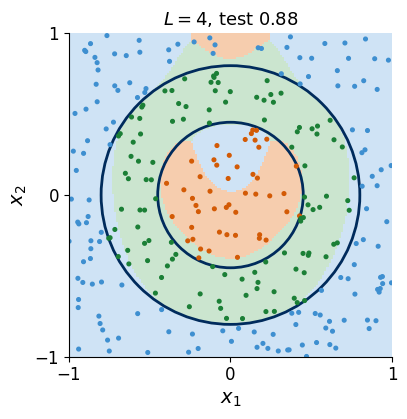

In [18]:
rng3 = np.random.default_rng(11)                    # data seed of the three-class study
R_DISC, R_RING = 0.45, 0.8
def make_three_class(M):
    X = rng3.uniform(-1, 1, size=(M, 2))
    r = np.sqrt((X ** 2).sum(1))
    return X, np.where(r < R_DISC, 0, np.where(r < R_RING, 1, 2))
X3tr, y3tr = make_three_class(600)
X3te, y3te = make_three_class(4000)
frac3 = np.bincount(y3te) / len(y3te)
print("class fractions in the test set (disc, ring, outside):", np.round(frac3, 3),
      f"; always answering the largest class gives {frac3.max():.3f}")

def state_matrix(params, x):                         # circuit (8) with the gate matrices (5), applied one by one
    theta, w = params
    xx = jnp.array([x[0], x[1], 0.0])
    psi = KET0
    for l in range(theta.shape[0]):
        psi = U(theta[l] + w[l] * xx) @ psi
    return psi

def fid3(params, x):                                 # F_c(x) of equation (10) for the three label states
    return jnp.abs(jnp.conj(LABELS3) @ state_matrix(params, x)) ** 2
fid3_batch = jax.jit(jax.vmap(fid3, in_axes=(None, 0)))

def loss3(params, X, y):                             # equation (11)
    F = jax.vmap(fid3, in_axes=(None, 0))(params, X)
    return jnp.mean(1 - F[jnp.arange(len(y)), y])

def accuracy3(params, X, y):                         # prediction (10)
    return float(np.mean(np.argmax(np.asarray(fid3_batch(params, X)), 1) == y))

def adam_steps(grad_fn, P0, X, y, steps=2000, lr=0.05):
    # Adam [4] written out with the constants of the recorded study; P is a list [theta, w]
    P = [jnp.array(p) for p in P0]
    m = [jnp.zeros_like(p) for p in P]; v = [jnp.zeros_like(p) for p in P]
    for t in range(1, steps + 1):
        gr = grad_fn(P, X, y)
        for i in range(2):
            m[i] = 0.9 * m[i] + 0.1 * gr[i]; v[i] = 0.999 * v[i] + 0.001 * gr[i] ** 2
            P[i] = P[i] - lr * (m[i] / (1 - 0.9 ** t)) / (jnp.sqrt(v[i] / (1 - 0.999 ** t)) + 1e-8)
    return P

grad3 = jax.jit(jax.grad(loss3))
res3, best3 = {}, {}

def fit_three(L, starts=4):
    if L not in res3:
        runs = []
        for s in range(starts):                      # offsets first, then weights, from one generator per start
            k = np.random.default_rng(50 * L + s)
            P0 = [k.uniform(-np.pi, np.pi, (L, 3)), k.normal(0, 2, (L, 3))]
            runs.append(adam_steps(grad3, P0, X3tr, y3tr))
        losses = [float(loss3(p, X3tr, y3tr)) for p in runs]
        b = int(np.argmin(losses))
        best3[L] = runs[b]
        res3[L] = dict(loss=losses[b], train_acc=accuracy3(runs[b], X3tr, y3tr), test_acc=accuracy3(runs[b], X3te, y3te))
    return res3[L]

t0 = time.perf_counter()
r = fit_three(4)
print(f"L = 4: loss {r['loss']:.4f}, training accuracy {r['train_acc']:.4f}, test accuracy {r['test_acc']:.4f}"
      f"  ({time.perf_counter() - t0:.1f} s)")
RESULTS["three_class_fractions"] = frac3.tolist()

CMAP3 = ListedColormap(["#F6CDAE", "#CBE5CF", "#CFE3F5"])
def draw_three(ax, L):
    Z = np.argmax(np.asarray(fid3_batch(best3[L], GRID)), 1).reshape(len(g), len(g))
    ax.pcolormesh(g, g, Z, cmap=CMAP3, shading="auto", vmin=0, vmax=2)
    for rr in (R_DISC, R_RING):
        draw_circle(ax, rr)
    sel = np.random.default_rng(12).choice(len(X3te), 300, replace=False)
    ax.scatter(X3te[sel, 0], X3te[sel, 1], c=[[ORANGE, GREEN, BLUE][c] for c in y3te[sel]], s=7)
    square_axes(ax); ax.set_title(f"$L={L}$, test {res3[L]['test_acc']:.2f}")

fig, ax = plt.subplots(figsize=(4.4, 4.2))
draw_three(ax, 4)
save(fig, "fig_lab073a_three_class_L4"); plt.show()

The shading shows the predicted class, orange for the disc, green for the ring and blue for the outside region, with the true boundaries in navy and test points coloured by their true class. Four layers already draw two closed boundaries. The errors lie along the two circles and near the centre of the disc, and the test accuracy lies well above the value 0.49 of always answering the largest class, the outside region.

An OPTIONAL cell trains the depths $L=1,2,6,8$ with the same settings in about two minutes when `RUN_OPTIONAL = True` and compares the accuracies with the recorded study; otherwise it plots the recorded study.

RUN_OPTIONAL is False: the curve below shows the recorded study


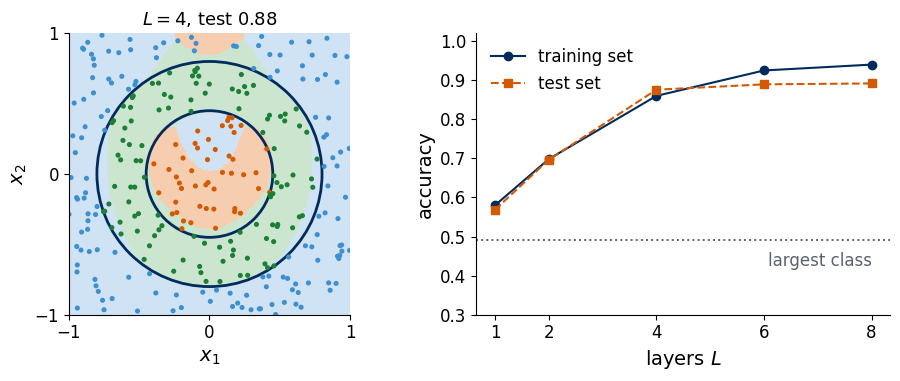

In [19]:
# OPTIONAL (about two minutes): the three-class classifier at L = 1, 2, 4, 6, 8, compared with the recorded study
RECORDED3 = {1: (0.5800, 0.5687), 2: (0.6983, 0.6967), 4: (0.8600, 0.8758), 6: (0.9250, 0.8895), 8: (0.9400, 0.8918)}
LS3 = [1, 2, 4, 6, 8]
if RUN_OPTIONAL:
    t0 = time.perf_counter()
    for L in LS3:
        r = fit_three(L)
        print(f"L = {L}: training accuracy {r['train_acc']:.4f}, test accuracy {r['test_acc']:.4f}"
              f"  (recorded {RECORDED3[L][0]:.4f}, {RECORDED3[L][1]:.4f})")
    dev = max(abs(res3[L]["test_acc"] - RECORDED3[L][1]) for L in LS3)
    print(f"{time.perf_counter() - t0:.1f} s; largest deviation of the test accuracy from the recorded study: {dev:.4f}")
    RESULTS["three_class"] = {L: res3[L] for L in LS3}
else:                                                # plot the recorded study; the L = 8 map needs the trained circuit
    for L in LS3:
        res3.setdefault(L, dict(train_acc=RECORDED3[L][0], test_acc=RECORDED3[L][1]))
    RESULTS["three_class"] = {L: dict(train_acc=RECORDED3[L][0], test_acc=RECORDED3[L][1], source="recorded") for L in LS3}
    print("RUN_OPTIONAL is False: the curve below shows the recorded study")

fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.0), gridspec_kw={"width_ratios": [1, 1.1]})
draw_three(axs[0], 8 if 8 in best3 else max(best3))
axs[1].plot(LS3, [res3[L]["train_acc"] for L in LS3], "o-", color=NAVY, label="training set")
axs[1].plot(LS3, [res3[L]["test_acc"] for L in LS3], "s--", color=ORANGE, label="test set")
axs[1].axhline(frac3.max(), color=GRAY, ls=":", lw=1.4)
axs[1].text(8, frac3.max() - 0.03, "largest class", color=GRAY, ha="right", va="top", fontsize=12)
axs[1].set_xlabel("layers $L$"); axs[1].set_ylabel("accuracy"); axs[1].set_ylim(0.3, 1.02); axs[1].set_xticks(LS3)
axs[1].legend(frameon=False, loc="upper left")
fig.tight_layout(); save(fig, "fig_lab073a_three_class"); plt.show()

The test accuracy rises from 0.57 at one layer to about 0.89 at six and eight layers, where it saturates, and the decision map at $L=8$ follows both circles. More layers give the output more frequencies (Section 9), which the classifier needs to draw two nested boundaries with a single qubit.

## 12. Classifiers with several qubits

A register of $N$ qubits offers more label states and more places to load the data. Its $2^N$ computational basis states are mutually orthogonal, so up to $2^N$ classes receive label states with zero pairwise fidelity, for instance $|00\rangle$, $|01\rangle$, $|10\rangle$ and $|11\rangle$ for four classes on two qubits. The fidelity (10) of the final state with a basis state is the probability of the corresponding bit string, so repeated measurements of all qubits estimate every $F_c$ at once, and the predicted class is the most frequent bit string.

The multi-qubit classifiers of Ref. [1] load the data into every qubit in every layer, each qubit with its own offsets and weights, and entangle the qubits with controlled-$Z$ gates after each layer except the last. The controlled-$Z$ gate
$$\widehat{\mathrm{CZ}}=\mathrm{diag}(1,1,1,-1) \tag{23}$$
multiplies the amplitude of $|11\rangle$ by $-1$. On four qubits Ref. [1] applies it to the pairs (1,2) and (3,4) in one layer and to (2,3) and (1,4) in the next. The last layer carries no $\widehat{\mathrm{CZ}}$, because a diagonal gate directly before a measurement in the computational basis changes only phases and leaves every probability unchanged. Ref. [1] also reads out each qubit separately, compares its reduced state with single-qubit label states and combines the fidelities of all qubits with trainable weights in the cost, which it calls the weighted-fidelity cost.

We build a two-qubit circuit with random angles, check that the fidelities with the four basis label states are the bit-string probabilities and sum to one, and check that a final $\widehat{\mathrm{CZ}}$ leaves these probabilities unchanged.

In [20]:
CZ = jnp.diag(jnp.array([1, 1, 1, -1], dtype=CDTYPE))             # equation (23)
BASIS2 = jnp.eye(4, dtype=CDTYPE)                                   # label states |00>, |01>, |10>, |11>

def two_qubit_state(params, x, cz_last=False):
    # both qubits load x in every layer; CZ after each layer except the last (unless cz_last)
    theta, w = params                                               # shapes (L, 2, 3)
    xx = pad(x)
    psi = BASIS2[0]
    L = theta.shape[0]
    for l in range(L):
        psi = jnp.kron(U(theta[l, 0] + w[l, 0] * xx), U(theta[l, 1] + w[l, 1] * xx)) @ psi
        if l < L - 1 or cz_last:
            psi = CZ @ psi
    return psi

kq = np.random.default_rng(21)
Pq = (jnp.array(kq.uniform(-np.pi, np.pi, (3, 2, 3))), jnp.array(kq.normal(0, 1, (3, 2, 3))))
xq = jnp.array([0.3, -0.6])
psi_q = two_qubit_state(Pq, xq)
F4 = np.abs(np.asarray(BASIS2.conj() @ psi_q)) ** 2                  # fidelities with the four label states
assert np.allclose(F4, np.abs(np.asarray(psi_q)) ** 2, atol=TOL) and abs(F4.sum() - 1) < TOL
assert np.allclose(np.abs(np.asarray(two_qubit_state(Pq, xq, cz_last=True))) ** 2, F4, atol=TOL)
print("fidelities with |00>, |01>, |10>, |11>:", np.round(F4, 4), "-> predicted class", int(np.argmax(F4)))
print("a final CZ leaves the four probabilities unchanged")

fidelities with |00>, |01>, |10>, |11>: [0.0906 0.2516 0.1171 0.5407] -> predicted class 3
a final CZ leaves the four probabilities unchanged


Ref. [1] trained such circuits on four problems, a circle, three circles and an annulus in the plane and a four-dimensional hypersphere. The table reproduces the test accuracies that it reports for two layers and the weighted-fidelity cost (values from Tables 1–4 of Ref. [1]).

| problem (classes, input dimension) | 1 qubit | 2 qubits, no CZ | 2 qubits, CZ | 4 qubits, no CZ | 4 qubits, CZ |
|---|---|---|---|---|---|
| circle (2, 2) | 0.94 | 0.96 | 0.96 | 0.96 | 0.96 |
| three circles (4, 2) | 0.76 | 0.90 | 0.83 | 0.90 | 0.89 |
| annulus (3, 2) | 0.76 | 0.79 | 0.82 | 0.87 | 0.96 |
| hypersphere (2, 4) | 0.87 | 0.92 | 0.91 | 0.90 | 0.98 |

Every multi-qubit circuit is more accurate than the single qubit in every problem. At two layers the $\widehat{\mathrm{CZ}}$ gates help the four-qubit circuits on the annulus and on the hypersphere and lower the two-qubit accuracy on three circles. With more layers most of these differences shrink, whereas on the hypersphere the entangled circuits stay ahead, with 0.97 against 0.93 for two qubits at four layers. The class of a point of the hypersphere depends on all four coordinates together, and the next section shows why entanglement matters in this situation.

## 13. Entanglement carries information to the read-out qubit

The role of the $\widehat{\mathrm{CZ}}$ gates becomes visible when the data are split over the qubits. We take points $\mathbf x=(x_1,x_2,x_3,x_4)$ drawn uniformly from $[-1,1]^4$ and assign class 1 to the points with $|\mathbf x|^2<4/\pi$. The volume of a four-dimensional ball of radius $\rho$ is $\pi^2\rho^4/2$, so this ball has half the volume 16 of the cube. Its radius $\sqrt{4/\pi}\approx1.13$ exceeds one, however, so part of the ball lies outside the cube, and class 1 holds slightly less than half of the points (the next cell prints 0.484). In every layer qubit 0 loads $(x_1,x_2,0)$ and qubit 1 loads $(x_3,x_4,0)$, each with its own offsets and weights. Only qubit 0 is measured, with the label states $|0\rangle$ and $|1\rangle$, the prediction (13) and the loss (14) applied to the probability $P(b_0=1\,|\,\mathbf x)$ of reading 1 on qubit 0. We compare this circuit without $\widehat{\mathrm{CZ}}$, the same circuit with a $\widehat{\mathrm{CZ}}$ after each layer except the last, and a single qubit that loads $(x_1,x_2,0)$ and then $(x_3,x_4,0)$ in every layer.

Without $\widehat{\mathrm{CZ}}$ the register stays in a product state $|a(x_1,x_2)\rangle\otimes|b(x_3,x_4)\rangle$, and the probability measured on qubit 0 depends on $x_1$ and $x_2$ alone. The probability of class 1 at given $x_1$ and $x_2$ depends only on $s=x_1^2+x_2^2$ and decreases with $s$, because a larger $s$ leaves less room for $x_3^2+x_4^2$, so the best rule of this kind predicts class 1 for $s$ below a threshold. With $\widehat{\mathrm{CZ}}$ written as $\hat I\otimes|0\rangle\langle0|+\hat Z\otimes|1\rangle\langle1|$, the gate applies $\hat Z$ to qubit 0 in the branch in which qubit 1 is in $|1\rangle$. The rotations of the next layer turn this relative phase into a change of the probabilities of qubit 0, which then depend on the amplitudes of qubit 1 and hence on $x_3$ and $x_4$.

We compute the best threshold rule on $s$ and check the mechanism with random angles. Without $\widehat{\mathrm{CZ}}$ a change of $x_3,x_4$ leaves the read-out probability unchanged, and with $\widehat{\mathrm{CZ}}$ it changes it.

In [21]:
rng4 = np.random.default_rng(4)                       # data seed of the entanglement study
R2_4D = np.sqrt(16 / np.pi ** 2)                     # |x|^2 < 4/pi: the ball has half the volume of [-1, 1]^4 but pokes out of it
def make_sphere4(M):
    X = rng4.uniform(-1, 1, size=(M, 4))
    return X, ((X ** 2).sum(1) < R2_4D).astype(np.float64)
X4tr, y4tr = make_sphere4(1000)
X4te, y4te = make_sphere4(4000)

s12 = (X4te[:, :2] ** 2).sum(1)                       # best rule that sees only x1, x2: threshold on s = x1^2 + x2^2
best_x12 = max(np.mean((s12 < c) == y4te) for c in np.linspace(0, 2, 401))
print(f"test fraction of class 1: {y4te.mean():.3f}; best accuracy of any rule using only x1, x2: {best_x12:.3f}")
RESULTS["entanglement_best_x1x2"] = float(best_x12)

def p1_split(params, x, ent):
    # qubit 0 loads (x1, x2, 0), qubit 1 loads (x3, x4, 0); returns P(b0 = 1 | x)
    theta, w = params                                 # shapes (L, 2, 3)
    xa = jnp.array([x[0], x[1], 0.0]); xb = jnp.array([x[2], x[3], 0.0])
    psi = jnp.zeros(4, dtype=CDTYPE).at[0].set(1.0)
    for l in range(theta.shape[0]):
        psi = jnp.kron(U(theta[l, 0] + w[l, 0] * xa), U(theta[l, 1] + w[l, 1] * xb)) @ psi
        if ent and l < theta.shape[0] - 1:
            psi = CZ @ psi
    pr = jnp.abs(psi) ** 2
    return pr[2] + pr[3]                               # amplitudes of |10> and |11>

def p1_both(params, x):
    # one qubit loads (x1, x2, 0) and then (x3, x4, 0) in every layer
    theta, w = params
    xa = jnp.array([x[0], x[1], 0.0]); xb = jnp.array([x[2], x[3], 0.0])
    psi = KET0
    for l in range(theta.shape[0]):
        psi = U(theta[l, 1] + w[l, 1] * xb) @ (U(theta[l, 0] + w[l, 0] * xa) @ psi)
    return jnp.abs(psi[1]) ** 2

ke = np.random.default_rng(22)
Pe = (jnp.array(ke.uniform(-np.pi, np.pi, (3, 2, 3))), jnp.array(ke.normal(0, 1.5, (3, 2, 3))))
xa_, xb_ = jnp.array([0.2, -0.4, 0.1, 0.7]), jnp.array([0.2, -0.4, -0.8, 0.3])     # same x1, x2, other x3, x4
d_no = abs(float(p1_split(Pe, xa_, False) - p1_split(Pe, xb_, False)))
d_cz = abs(float(p1_split(Pe, xa_, True) - p1_split(Pe, xb_, True)))
assert d_no < TOL and d_cz > 1e-3
print(f"change of P(b0 = 1) when only x3, x4 change: without CZ {d_no:.1e}, with CZ {d_cz:.3f}")

# The same two models evaluated for all points of a batch at once, with the entries of U(phi) written out:
# U = [[e^{-i(a+c)/2} cos(b/2), -e^{i(a-c)/2} sin(b/2)], [e^{-i(a-c)/2} sin(b/2), e^{i(a+c)/2} cos(b/2)]].
# Training uses these; they agree with the gate-by-gate versions above to rounding error.
def gate_entries(phi):                                # phi has shape (M, 3)
    a, b, c = phi[:, 0], phi[:, 1], phi[:, 2]
    cb, sb = jnp.cos(b / 2), jnp.sin(b / 2)
    ep, em = jnp.exp(-0.5j * (a + c)), jnp.exp(-0.5j * (a - c))
    return ep * cb, -jnp.conj(em) * sb, em * sb, jnp.conj(ep) * cb

def pad2(X, i, j):
    return jnp.stack([X[:, i], X[:, j], jnp.zeros(X.shape[0])], 1)

CZ_SIGNS = jnp.array([[1, 1], [1, -1]], dtype=CDTYPE)          # CZ flips the sign of |11>

def p1_split_batch(params, X, ent):
    theta, w = params
    xa, xb = pad2(X, 0, 1), pad2(X, 2, 3)
    psi = jnp.zeros((X.shape[0], 2, 2), dtype=CDTYPE).at[:, 0, 0].set(1.0)   # psi[m, i, j]: amplitude of |i j>
    for l in range(theta.shape[0]):
        u00, u01, u10, u11 = gate_entries(theta[l, 0] + w[l, 0] * xa)       # gate on qubit 0
        psi = jnp.stack([u00[:, None] * psi[:, 0] + u01[:, None] * psi[:, 1],
                         u10[:, None] * psi[:, 0] + u11[:, None] * psi[:, 1]], 1)
        u00, u01, u10, u11 = gate_entries(theta[l, 1] + w[l, 1] * xb)       # gate on qubit 1
        psi = jnp.stack([u00[:, None] * psi[:, :, 0] + u01[:, None] * psi[:, :, 1],
                         u10[:, None] * psi[:, :, 0] + u11[:, None] * psi[:, :, 1]], 2)
        if ent and l < theta.shape[0] - 1:
            psi = psi * CZ_SIGNS
    return (jnp.abs(psi[:, 1]) ** 2).sum(1)

def p1_both_batch(params, X):
    theta, w = params
    xa, xb = pad2(X, 0, 1), pad2(X, 2, 3)
    psi = jnp.zeros((X.shape[0], 2), dtype=CDTYPE).at[:, 0].set(1.0)
    for l in range(theta.shape[0]):
        for k, xx in ((0, xa), (1, xb)):
            u00, u01, u10, u11 = gate_entries(theta[l, k] + w[l, k] * xx)
            # stack into one array: written as two coupled scalars, the compiler duplicates work at every gate
            psi = jnp.stack([u00 * psi[:, 0] + u01 * psi[:, 1], u10 * psi[:, 0] + u11 * psi[:, 1]], 1)
    return jnp.abs(psi[:, 1]) ** 2

Xc = jnp.array(X4te[:50])
for ent in (False, True):
    assert np.allclose(p1_split_batch(Pe, Xc, ent), jax.vmap(p1_split, in_axes=(None, 0, None))(Pe, Xc, ent), atol=1e-12)
assert np.allclose(p1_both_batch(Pe, Xc), jax.vmap(p1_both, in_axes=(None, 0))(Pe, Xc), atol=1e-12)
print("batched circuits agree with the gate-by-gate circuits")


test fraction of class 1: 0.484; best accuracy of any rule using only x1, x2: 0.750


change of P(b0 = 1) when only x3, x4 change: without CZ 2.2e-16, with CZ 0.021


batched circuits agree with the gate-by-gate circuits


The best rule that uses only $x_1$ and $x_2$ classifies three quarters of the test points correctly, and this value bounds the circuit without $\widehat{\mathrm{CZ}}$ at every depth. The printed differences confirm the mechanism. Without $\widehat{\mathrm{CZ}}$ the read-out probability does not change when only $x_3$ and $x_4$ change, and with $\widehat{\mathrm{CZ}}$ it does.

An optional cell trains the three models at $L=1,2,3,4,6$, each from four starts with the seeds $10L+s$, offsets uniform in $[-\pi,\pi]$, weights normal with standard deviation 1.5 and 2000 Adam steps with the step size 0.05, and compares the accuracies with the recorded study. The four starts are trained together, and each circuit is evaluated for all data points at once, so the whole study takes about eight minutes instead of half an hour. With `RUN_OPTIONAL = False` the cell plots the recorded study.

In [22]:
# OPTIONAL (about eight minutes on a laptop CPU): entanglement study at L = 1, 2, 3, 4, 6, compared with the recorded study
# recorded (training accuracy, test accuracy) of the best of four starts
RECORDED_ENT = {("one qubit, both inputs", 1): (0.7170, 0.6560), ("one qubit, both inputs", 2): (0.8120, 0.7680), ("one qubit, both inputs", 3): (0.8060, 0.7585), ("one qubit, both inputs", 4): (0.8170, 0.7800), ("one qubit, both inputs", 6): (0.8770, 0.8570), ("two qubits, no CZ", 1): (0.6720, 0.6633), ("two qubits, no CZ", 2): (0.6860, 0.6805), ("two qubits, no CZ", 3): (0.7220, 0.7232), ("two qubits, no CZ", 4): (0.7190, 0.7280), ("two qubits, no CZ", 6): (0.7480, 0.7490), ("two qubits with CZ", 1): (0.6720, 0.6633), ("two qubits with CZ", 2): (0.7400, 0.6640), ("two qubits with CZ", 3): (0.7280, 0.6910), ("two qubits with CZ", 4): (0.7940, 0.7715), ("two qubits with CZ", 6): (0.8460, 0.8040)}
ENT_MODELS = {"one qubit, both inputs": p1_both_batch,
              "two qubits, no CZ": lambda P, X: p1_split_batch(P, X, False),
              "two qubits with CZ": lambda P, X: p1_split_batch(P, X, True)}
LS4 = [1, 2, 3, 4, 6]

def train_four_starts(fun, L, steps=2000, lr=0.05):
    # the four starts (seeds 10L + s) are trained together: vmap over starts, one compiled Adam step [4]
    loss = lambda P: jnp.mean(y4tr * (1 - fun(P, X4tr)) + (1 - y4tr) * fun(P, X4tr))      # equation (14)
    @jax.jit
    def step(P, m, v, t):
        g = jax.vmap(jax.grad(loss))(P)
        m = [0.9 * a + 0.1 * b for a, b in zip(m, g)]
        v = [0.999 * a + 0.001 * b ** 2 for a, b in zip(v, g)]
        return [p - lr * (a / (1 - 0.9 ** t)) / (jnp.sqrt(b / (1 - 0.999 ** t)) + 1e-8) for p, a, b in zip(P, m, v)], m, v
    gens = [np.random.default_rng(10 * L + s) for s in range(4)]
    th0 = np.stack([k.uniform(-np.pi, np.pi, (L, 2, 3)) for k in gens])
    w0 = np.stack([k.normal(0, 1.5, (L, 2, 3)) for k in gens])
    P = [jnp.array(th0), jnp.array(w0)]
    m = [jnp.zeros_like(p) for p in P]; v = [jnp.zeros_like(p) for p in P]
    for t in range(1, steps + 1):
        P, m, v = step(P, m, v, float(t))
    losses = np.asarray(jax.vmap(loss)(P))
    b = int(np.argmin(losses))
    return [P[0][b], P[1][b]], float(losses[b])

res4 = {}
if RUN_OPTIONAL:
    X4tr, y4tr = jnp.array(X4tr), jnp.array(y4tr)
    t0 = time.perf_counter()
    for name, fun in ENT_MODELS.items():
        for L in LS4:
            P, lo = train_four_starts(fun, L)
            acc_of = lambda X, y: float(np.mean((np.asarray(fun(P, jnp.array(X))) > 0.5) == np.asarray(y)))
            res4[(name, L)] = dict(loss=lo, train_acc=acc_of(X4tr, y4tr), test_acc=acc_of(X4te, y4te))
            print(f"{name:24s} L = {L}: training accuracy {res4[(name, L)]['train_acc']:.4f},"
                  f" test accuracy {res4[(name, L)]['test_acc']:.4f} (recorded {RECORDED_ENT[(name, L)][1]:.4f})"
                  f"  ({time.perf_counter() - t0:.0f} s)", flush=True)
    dev = max(abs(res4[k]["test_acc"] - RECORDED_ENT[k][1]) for k in res4)
    print(f"largest deviation of the test accuracy from the recorded study: {dev:.4f}")
    RESULTS["entanglement"] = {f"{n}, L={L}": res4[(n, L)] for (n, L) in res4}
    RESULTS["entanglement_seconds"] = time.perf_counter() - t0
else:
    res4 = {k: dict(train_acc=v[0], test_acc=v[1]) for k, v in RECORDED_ENT.items()}
    RESULTS["entanglement"] = {f"{n}, L={L}": dict(res4[(n, L)], source="recorded") for (n, L) in res4}
    print("RUN_OPTIONAL is False: the figure below shows the recorded study")


RUN_OPTIONAL is False: the figure below shows the recorded study


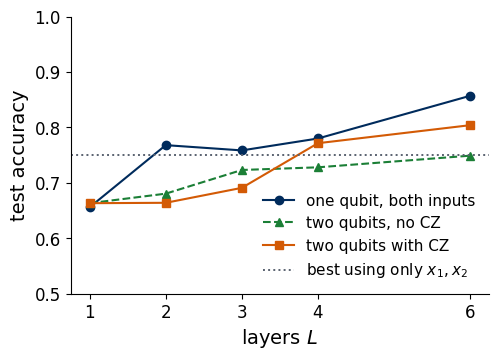

In [23]:
fig, ax = plt.subplots(figsize=(5.4, 3.6))
for name, col, st in (("one qubit, both inputs", NAVY, "o-"), ("two qubits, no CZ", GREEN, "^--"), ("two qubits with CZ", ORANGE, "s-")):
    ax.plot(LS4, [res4[(name, L)]["test_acc"] for L in LS4], st, color=col, label=name)
ax.axhline(best_x12, color=GRAY, ls=":", lw=1.4, label="best using only $x_1, x_2$")
ax.set_xlabel("layers $L$"); ax.set_ylabel("test accuracy"); ax.set_ylim(0.5, 1.0); ax.set_xticks(LS4)
ax.legend(frameon=False, loc="lower right", fontsize=11)
save(fig, "fig_lab073a_entanglement"); plt.show()


The dotted line is the best accuracy of any rule that uses only $x_1$ and $x_2$. The circuit without $\widehat{\mathrm{CZ}}$ approaches this line and stays below it at every depth, because its read-out qubit never receives $x_3$ and $x_4$. With $\widehat{\mathrm{CZ}}$ the accuracy passes the line from four layers on and reaches 0.80 at six layers, so information from qubit 1 arrives at the read-out qubit through the entangling gates. The single qubit that loads all four inputs reaches 0.86 at six layers. Entanglement is therefore needed when the data are distributed over several qubits and the class depends on all of them together.

## 14. Two qubits on an annulus

When every qubit loads all inputs, the gain from entanglement is smaller, as we show on a task with two boundaries. We label as class 1 the points of an annulus, $0.4<r<0.8$ with $r=|\mathbf x|$, and as class 0 the points inside the inner circle and outside the outer one. The annulus covers the fraction $\pi(0.8^2-0.4^2)/4\approx0.38$ of the square, so a classifier that always answers 0 reaches an accuracy of about 0.63 on the test set, which is the baseline for this task. We use 500 training and 4000 test points.

Two qubits have four amplitudes, ordered as $|00\rangle,|01\rangle,|10\rangle,|11\rangle$, with qubit 0 as the left factor of every Kronecker product, and a pair of one-qubit gates acts as $\hat U_0\otimes\hat U_1$. Acting on the product state $|{+}\rangle|{+}\rangle$, with $|{+}\rangle=(|0\rangle+|1\rangle)/\sqrt2$, the controlled-$Z$ gate (23) produces $(|00\rangle+|01\rangle+|10\rangle-|11\rangle)/2$, which cannot be written as a product of two one-qubit states, so the gate entangles the qubits. Each layer of the two-qubit classifier of Section 12 applies a re-uploading gate to each qubit, with its own offsets and weights, and then $\widehat{\mathrm{CZ}}$,
$$|\psi(\mathbf x)\rangle=\Big[\hat U(\boldsymbol\theta_{L,0}+\mathbf w_{L,0}\circ\mathbf x)\otimes\hat U(\boldsymbol\theta_{L,1}+\mathbf w_{L,1}\circ\mathbf x)\Big]\,\widehat{\mathrm{CZ}}\cdots\widehat{\mathrm{CZ}}\,\Big[\hat U(\boldsymbol\theta_{1,0}+\mathbf w_{1,0}\circ\mathbf x)\otimes\hat U(\boldsymbol\theta_{1,1}+\mathbf w_{1,1}\circ\mathbf x)\Big]|00\rangle , \tag{24}$$
where the second index of $\boldsymbol\theta_{\ell,q}$ and $\mathbf w_{\ell,q}$ is the qubit $q=0,1$. The circuit has $12L$ trainable numbers. As in Section 12, the last layer has no $\widehat{\mathrm{CZ}}$.

The label states are $|00\rangle$ for class 0 and $|11\rangle$ for class 1. The model output is the average probability of outcome 1 on the two qubits,
$$\bar P(1\,|\,\mathbf x)=\frac12\Big[P(b_0=1\,|\,\mathbf x)+P(b_1=1\,|\,\mathbf x)\Big], \tag{25}$$
where $b_q$ is the measured bit of qubit $q$. The prediction (13) and the loss (14) are used with $\bar P$ in place of $P$, and the loss is then the infidelity of each qubit with its label state, averaged over the two qubits. Without the $\widehat{\mathrm{CZ}}$ gates the two qubits never interact, each one is a separate single-qubit classifier, and (25) averages their outputs. With $\widehat{\mathrm{CZ}}$ the qubits exchange information in every layer. The comparison between these two cases with the same number of parameters isolates the effect of the entangling gate, and one qubit with $6L$ parameters serves as reference.

annulus: fraction of class 1 = 0.358 (training), 0.372 (test); always answering 0 gives accuracy 0.627


Schmidt coefficients of CZ|+>|+>: [0.7071 0.7071] (a product state has one nonzero value)


tensor implementation agrees with the Kronecker-product matrices
without CZ the two-qubit output is the average of two one-qubit classifiers


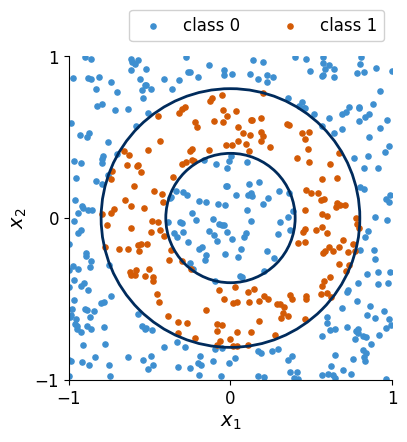

In [24]:
rng5 = np.random.default_rng(5)
def make_annulus_data(M):
    X = rng5.uniform(-1, 1, size=(M, 2))
    r = np.sqrt((X ** 2).sum(1))
    return X, ((r > 0.4) & (r < 0.8)).astype(np.float64)
Xa_tr, ya_tr = make_annulus_data(500)
Xa_te, ya_te = make_annulus_data(4000)
baseline = 1 - ya_te.mean()
print(f"annulus: fraction of class 1 = {ya_tr.mean():.3f} (training), {ya_te.mean():.3f} (test);"
      f" always answering 0 gives accuracy {baseline:.3f}")
RESULTS["annulus_baseline"] = float(baseline)

plus = jnp.array([1, 1], dtype=CDTYPE) / jnp.sqrt(2)
ent = (CZ @ jnp.kron(plus, plus)).reshape(2, 2)                      # amplitude matrix psi[b0, b1]
schmidt = jnp.linalg.svd(ent, compute_uv=False)
assert jnp.allclose(schmidt, jnp.array([1, 1]) / jnp.sqrt(2), atol=TOL)    # two equal Schmidt values: entangled
print("Schmidt coefficients of CZ|+>|+>:", np.round(np.asarray(schmidt), 4), "(a product state has one nonzero value)")

def p1_two(params, x, entangle):                                      # equation (25) for circuit (24)
    theta, w = params                                                 # shapes (L, 2, 3)
    xx = pad(x)
    L = theta.shape[0]
    cz_sign = jnp.array([[1, 1], [1, -1]], dtype=CDTYPE)             # CZ on the tensor psi[b0, b1]
    def layer(psi, inp):                                              # psi[b0, b1], shape (2, 2)
        t, ww, l = inp
        psi = apply_U(psi, t[0] + ww[0] * xx)                         # qubit 0 acts on the first axis
        psi = apply_U(psi.T, t[1] + ww[1] * xx).T                     # qubit 1 acts on the second axis
        if entangle:
            psi = jnp.where(l < L - 1, cz_sign * psi, psi)              # no CZ after the last layer
        return psi, None
    psi0 = jnp.zeros((2, 2), dtype=CDTYPE).at[0, 0].set(1.0)
    psi, _ = lax.scan(layer, psi0, (theta, w, jnp.arange(L)))
    pr = (jnp.abs(psi) ** 2).reshape(-1)                              # order |00>, |01>, |10>, |11>
    return 0.5 * ((pr[2] + pr[3]) + (pr[1] + pr[3]))                  # [P(b0 = 1) + P(b1 = 1)] / 2

def two_qubit_loss(entangle):
    def loss(params, X, y):
        q = jax.vmap(lambda x: p1_two(params, x, entangle))(X)
        return jnp.mean(y * (1 - q) + (1 - y) * q)
    return loss

# check: without CZ, the output is the mean of two independent one-qubit classifiers
thq, wq = jax.random.normal(jax.random.PRNGKey(3), (3, 2, 3)), jax.random.normal(jax.random.PRNGKey(4), (3, 2, 3))
for xv in Xa_tr[:4]:
    assert abs(p1_two((thq, wq), xv, False) - 0.5 * (p1((thq[:, 0], wq[:, 0]), xv) + p1((thq[:, 1], wq[:, 1]), xv))) < TOL
xv = jnp.array(Xa_tr[0]); psi_k = jnp.zeros(4, dtype=CDTYPE).at[0].set(1.0)
for l in range(3):                                                    # Kronecker-matrix version of (24)
    psi_k = jnp.kron(U(thq[l, 0] + wq[l, 0] * pad(xv)), U(thq[l, 1] + wq[l, 1] * pad(xv))) @ psi_k
    psi_k = CZ @ psi_k if l < 2 else psi_k
pk = jnp.abs(psi_k) ** 2
assert abs(p1_two((thq, wq), xv, True) - 0.5 * (pk[2] + pk[3] + pk[1] + pk[3])) < TOL
print("tensor implementation agrees with the Kronecker-product matrices")
print("without CZ the two-qubit output is the average of two one-qubit classifiers")

fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.scatter(*Xa_tr[ya_tr == 0].T, s=14, color=BLUE, label="class 0")
ax.scatter(*Xa_tr[ya_tr == 1].T, s=14, color=ORANGE, label="class 1")
for r in (0.4, 0.8):
    draw_circle(ax, r)
square_axes(ax)
ax.legend(frameon=True, framealpha=0.9, loc="upper right", bbox_to_anchor=(1.0, 1.17), ncol=2)
save(fig, "fig_lab073a_annulus_data"); plt.show()

The orange points of class 1 fill the ring between the two navy circles, and the blue points of class 0 fill the centre and the corners. A boundary that encloses a disc is no longer enough, because the classifier has to draw a ring.

The training settings differ from the circle task. With the settings of Section 7 (four or fewer starts, 1500 steps, weights from a standard normal distribution), many runs on this task end with a circuit that predicts class 0 everywhere. This is a local minimum of the loss (14) with an accuracy equal to the baseline of always answering 0, and on the annulus it is reached easily because class 0 is the majority. We therefore train each model from six random starts, run 2500 Adam steps with the step size 0.05, and draw the initial weights from a normal distribution of standard deviation 2. Larger weights give the circuit higher frequencies in $\mathbf x$ from the start (Section 9), so the outputs of a fresh circuit already vary over the square and fewer starts end in the trivial minimum.

The classroom cell trains the three models with $L=5$ layers, six starts each, and takes about a minute.

L = 5, one qubit           : 30 parameters, training accuracy 0.908, test accuracy 0.910


L = 5, two qubits, no CZ   : 60 parameters, training accuracy 0.932, test accuracy 0.915


L = 5, two qubits with CZ  : 60 parameters, training accuracy 0.938, test accuracy 0.937
211.4 s


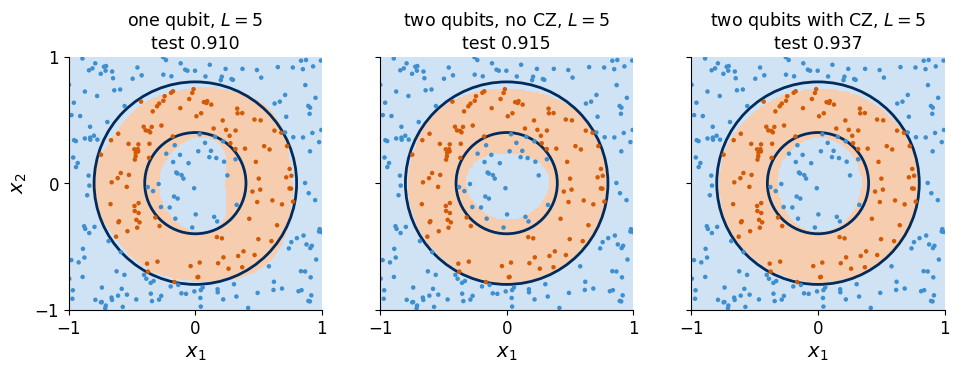

In [25]:
MODELS = [("one qubit", 1, False, NAVY, "o-"), ("two qubits, no CZ", 2, False, GREEN, "^--"),
          ("two qubits with CZ", 2, True, ORANGE, "s-")]
STEPS_A, LR_A, STARTS_A, W_STD_A = 2500, 0.05, 6, 2.0
loss_fns = {"one qubit": loss_infidelity, "two qubits, no CZ": two_qubit_loss(False), "two qubits with CZ": two_qubit_loss(True)}
trainers = {name: make_trainer(fn, steps=STEPS_A, lr=LR_A) for name, fn in loss_fns.items()}
p1_fns = {"one qubit": p1_batch,
          "two qubits, no CZ": jax.jit(jax.vmap(lambda P, x: p1_two(P, x, False), in_axes=(None, 0))),
          "two qubits with CZ": jax.jit(jax.vmap(lambda P, x: p1_two(P, x, True), in_axes=(None, 0)))}
res2, best2 = {}, {}

def fit_annulus(name, nq, entangle, L, starts=STARTS_A):
    if (name, L) not in res2:
        seeds = [1000 * L + 10 * nq + int(entangle) + s for s in range(starts)]
        th, w = initial_params(L, seeds, shape=(nq, 3), w_std=W_STD_A)
        if nq == 1:
            th, w = th[:, :, 0, :], w[:, :, 0, :]
        P, _ = trainers[name]((th, w), Xa_tr, ya_tr)
        final = [float(loss_fns[name]((P[0][i], P[1][i]), Xa_tr, ya_tr)) for i in range(starts)]
        b = int(np.argmin(final))                  # start with the lowest training loss
        Pb = (P[0][b], P[1][b])
        res2[(name, L)] = dict(params=6 * nq * L, train_loss=final[b],
                               train_acc=accuracy(p1_fns[name](Pb, Xa_tr), ya_tr), test_acc=accuracy(p1_fns[name](Pb, Xa_te), ya_te))
        best2[(name, L)] = Pb
    return res2[(name, L)]

L_CLASS = 5
t0 = time.perf_counter()
for name, nq, entangle, _, _ in MODELS:
    r = fit_annulus(name, nq, entangle, L_CLASS)
    print(f"L = {L_CLASS}, {name:20s}: {r['params']:2d} parameters, training accuracy {r['train_acc']:.3f}, test accuracy {r['test_acc']:.3f}")
print(f"{time.perf_counter() - t0:.1f} s")
RESULTS["annulus_classroom"] = {f"{name}, L={L_CLASS}": res2[(name, L_CLASS)] for name, *_ in MODELS}

fig, axs = plt.subplots(1, 3, figsize=(10.0, 3.5))
pts_a = np.random.default_rng(11).choice(len(Xa_te), 300, replace=False)
for ax, (name, nq, entangle, col, _) in zip(axs, MODELS):
    Z = (np.asarray(p1_fns[name](best2[(name, L_CLASS)], GRID)) > 0.5).reshape(len(g), len(g))
    ax.pcolormesh(g, g, Z, cmap=CLASS_CMAP, shading="auto", vmin=0, vmax=1)
    for r in (0.4, 0.8):
        draw_circle(ax, r)
    ax.scatter(Xa_te[pts_a, 0], Xa_te[pts_a, 1], c=[ORANGE if t else BLUE for t in ya_te[pts_a]], s=5)
    square_axes(ax); ax.set_title(f"{name}, $L={L_CLASS}$\ntest {res2[(name, L_CLASS)]['test_acc']:.3f}", fontsize=12.5)
    if name != MODELS[0][0]:
        ax.set_ylabel(""); ax.set_yticklabels([])
fig.tight_layout(); save(fig, "fig_lab073a_2q_maps_L5"); plt.show()

The three panels show the decision maps of the three models with five layers, with the true annulus in navy. All three models now draw a ring and separate the centre from the annulus, with deviations along both circles. The entangled circuit reaches a slightly higher test accuracy, 0.94 against 0.91 for the single qubit and 0.91 for the two uncoupled qubits. The two-qubit models have the same number of parameters, $12L$, and differ only by the $\widehat{\mathrm{CZ}}$ gates. Each model is the best of six starts, and the optional scan below shows that differences of this size between the two-qubit models change sign from one depth to the next, whereas the number of uploads changes the accuracy much more.

### 14.1 Dependence on the number of layers (optional)

We repeat the comparison for $L=1,\dots,5$ with the same settings, six starts per model and depth. The scan compiles twelve additional training loops and takes about two and a half minutes and runs only with `RUN_OPTIONAL = True`; otherwise the figure shows the recorded study.

RUN_OPTIONAL is False: depths 1 to 4 show the recorded study


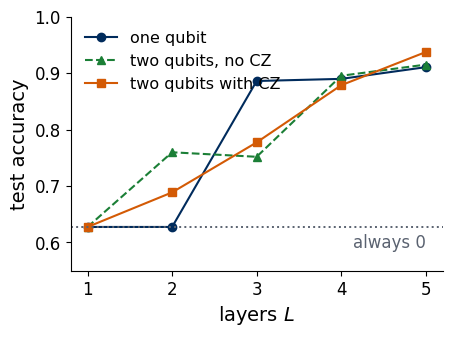

In [26]:
# OPTIONAL, longer: all three models for L = 1..5, six starts each (L = 5 is reused from the classroom cell)
LS2 = [1, 2, 3, 4, 5]
RECORDED_ANNULUS = {"one qubit, L=1": {'params': 6, 'train_acc': 0.642, 'test_acc': 0.6275}, "one qubit, L=2": {'params': 12, 'train_acc': 0.642, 'test_acc': 0.6275}, "one qubit, L=3": {'params': 18, 'train_acc': 0.888, 'test_acc': 0.886}, "one qubit, L=4": {'params': 24, 'train_acc': 0.9, 'test_acc': 0.88975}, "one qubit, L=5": {'params': 30, 'train_acc': 0.908, 'test_acc': 0.9105}, "two qubits, no CZ, L=1": {'params': 12, 'train_acc': 0.642, 'test_acc': 0.6275}, "two qubits, no CZ, L=2": {'params': 24, 'train_acc': 0.764, 'test_acc': 0.75975}, "two qubits, no CZ, L=3": {'params': 36, 'train_acc': 0.762, 'test_acc': 0.75175}, "two qubits, no CZ, L=4": {'params': 48, 'train_acc': 0.896, 'test_acc': 0.89525}, "two qubits, no CZ, L=5": {'params': 60, 'train_acc': 0.932, 'test_acc': 0.915}, "two qubits with CZ, L=1": {'params': 12, 'train_acc': 0.642, 'test_acc': 0.6275}, "two qubits with CZ, L=2": {'params': 24, 'train_acc': 0.688, 'test_acc': 0.68875}, "two qubits with CZ, L=3": {'params': 36, 'train_acc': 0.772, 'test_acc': 0.77725}, "two qubits with CZ, L=4": {'params': 48, 'train_acc': 0.882, 'test_acc': 0.8785}, "two qubits with CZ, L=5": {'params': 60, 'train_acc': 0.938, 'test_acc': 0.93725}}
if RUN_OPTIONAL:
    t0 = time.perf_counter()
    for name, nq, entangle, _, _ in MODELS:
        for L in LS2:
            r = fit_annulus(name, nq, entangle, L)
        print(f"{name:20s} test accuracy for L = 1..5:", [round(res2[(name, L)]['test_acc'], 3) for L in LS2])
    print(f"{time.perf_counter() - t0:.1f} s")
    RESULTS["annulus"] = {f"{name}, L={L}": res2[(name, L)] for name, *_ in MODELS for L in LS2}
else:                                                # recorded study for the depths not trained above
    for name, *_ in MODELS:
        for L in LS2:
            res2.setdefault((name, L), RECORDED_ANNULUS[f"{name}, L={L}"])
    RESULTS["annulus"] = {f"{name}, L={L}": res2[(name, L)] for name, *_ in MODELS for L in LS2}
    print("RUN_OPTIONAL is False: depths 1 to 4 show the recorded study")

fig, ax = plt.subplots(figsize=(4.8, 3.3))
for name, nq, entangle, col, st in MODELS:
    ax.plot(LS2, [res2[(name, L)]["test_acc"] for L in LS2], st, color=col, label=name)
ax.axhline(baseline, color=GRAY, ls=":", lw=1.4); ax.text(5, baseline - 0.012, "always 0", color=GRAY, ha="right", va="top", fontsize=12)
ax.set_xlabel("layers $L$"); ax.set_ylabel("test accuracy"); ax.set_ylim(0.55, 1.0); ax.set_xticks(LS2)
ax.legend(frameon=False, loc="upper left", fontsize=11.5)
save(fig, "fig_lab073a_2q_accuracy"); plt.show()

The figure shows the test accuracy of the three models against the number of layers, with the baseline of always answering 0 as a dotted line. With one layer every model stays at the baseline, since a single upload gives straight bands (Section 4) and no band beats always answering 0 on this task. All three models need several uploads before they draw the two circles. From three layers on their accuracies lie between about 0.75 and 0.9, and at five layers all three exceed 0.9. The curves cross each other at intermediate depths, the single qubit leads at $L=3$ and the uncoupled qubits at $L=4$, and the entangled circuit leads only at $L=5$, by about 0.02. On this small task the number of uploads therefore matters more than the entangling gate. Each point is the best of six starts, and with so few starts a difference of a few hundredths between two models at one depth does not rank them reliably.

## 15. Exercises

1. Split the square into four classes, $c=2\,y(\mathbf x)+[x_1>0]$, with $y$ from rule (1) and $[x_1>0]$ equal to 1 for $x_1>0$ and 0 otherwise. Use as label states the four states $|\psi_c\rangle$ whose Bloch vectors point to the corners of a regular tetrahedron (`LABELS4` of Section 6), train circuit (8) with the loss $\frac1M\sum_m\big(1-|\langle\psi_{c_m}|\psi(\mathbf x_m)\rangle|^2\big)$, and predict the class with the largest fidelity. Plot the test accuracy against $L$.
2. On a device $P(1\,|\,\mathbf x)$ is estimated from $S$ repeated measurements as $\tilde P=n_1/S$, where $n_1$ counts the outcomes 1 and follows a binomial distribution. Evaluate the trained $L=6$ circle classifier with $\tilde P$ in place of $P$ for $S=1,10,100,1000$ and plot the test accuracy against $S$. Explain with Section 8 which test points change their predicted label and why the accuracy saturates.
3. Remove the trainable weights, $\mathbf w_\ell=(1,1,1)$ in every layer, and repeat Section 10. Relate the result to the remark after equation (21) about rescaled frequencies.
4. Fit the target $g(x)+0.2\cos4x$ with the model (17) for $L=3$ and $L=4$. Then keep $L=2$ and replace the encoding gate by $\hat S(2x)$, and explain with equation (21) which frequencies this model can produce.
5. Train the circle classifier at $L=6$ with 50, 100 and 400 training points and compare the gap between the training and the test accuracy.
6. Train the two-qubit classifier of Section 12 on four classes of the square, $c=2\,y(\mathbf x)+[x_1>0]$ as in Exercise 1, with the basis states $|00\rangle,|01\rangle,|10\rangle,|11\rangle$ as label states and the loss (11). Compare its test accuracy with the single qubit of Exercise 1 at equal depth.


In [27]:
RESULTS["runtime_seconds"] = time.perf_counter() - started
(RES / "lab073a_results.json").write_text(json.dumps(RESULTS, indent=2, default=float))
print(f"results written to {RES / 'lab073a_results.json'}")
print(f"runtime of the whole notebook: {RESULTS['runtime_seconds']:.1f} s")

results written to classroom_results/lab073a_results.json
runtime of the whole notebook: 458.2 s


## 16. Summary

A single qubit becomes a classifier when the data set its rotation angles and a measurement returns the class. Each class is assigned a label state, the poles of the Bloch sphere for two classes, Bloch vectors $120^\circ$ apart for three and the corners of a tetrahedron for four, the class of largest fidelity is predicted, training minimises the average infidelity with these states, and the decision boundary is the set of data points that the circuit maps onto the equator. A single upload of the data gives an output that depends on one affine combination of the coordinates, so it can only draw straight bands. Loading the data again in every layer, with trainable offsets and weights, produces nested functions of the data that bend and close the boundary, and the accuracy on unseen test points rises with the number of layers. The Fourier picture explains this growth, since with $L$ uploads the output is a trigonometric polynomial with frequencies up to $L$, the encoding fixes the available frequencies and the trainable gates set the coefficients, which a fit of a target with three frequencies confirms. For one input variable a single qubit can express every Fourier series, whereas for several variables universality relies on the trainable weights on the data. The same circuit separates three classes, a disc, a ring and the outside region. Registers of $N$ qubits offer $2^N$ orthogonal basis states as label states. When the inputs are split over two qubits and only one qubit is read out, the circuit without controlled-$Z$ gates cannot exceed the best rule that uses the inputs of that qubit alone, and the entangled circuit passes this limit because the gates carry information to the read-out qubit. On a ring-shaped class loaded into both qubits with a boundary made of two circles, one qubit, two uncoupled qubits and two qubits coupled by controlled-$Z$ gates all needed several uploads, and the entangled circuit was only slightly more accurate at five layers, so on this small task the number of uploads mattered more than entanglement. Throughout, the probabilities and gradients were exact results of a state-vector simulation, whereas a device would estimate them from repeated measurements and the parameter-shift rule.

## References

[1] A. Pérez-Salinas, A. Cervera-Lierta, E. Gil-Fuster, and J. I. Latorre, Data re-uploading for a universal quantum classifier, Quantum **4**, 226 (2020), [doi:10.22331/q--226](https://doi.org/10.22331/q--226).

[2] A. Pérez-Salinas, D. López-Núñez, A. García-Sáez, P. Forn-Díaz, and J. I. Latorre, One qubit as a universal approximant, Phys. Rev. A **104**, 012405 (2021), [doi:10.1103/PhysRevA.104.012405](https://doi.org/10.1103/PhysRevA.104.012405).

[3] M. Schuld, R. Sweke, and J. J. Meyer, Effect of data encoding on the expressive power of variational quantum-machine-learning models, Phys. Rev. A **103**, 032430 (2021), [doi:10.1103/PhysRevA.103.032430](https://doi.org/10.1103/PhysRevA.103.032430).

[4] D. P. Kingma and J. Ba, Adam: A method for stochastic optimization, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980) (2014).

[5] Z. Yu, H. Yao, M. Li, and X. Wang, Power and limitations of single-qubit native quantum neural networks, in Advances in Neural Information Processing Systems **35**, 27810 (2022), [arXiv:2205.07848](https://arxiv.org/abs/2205.07848).